<p class="lead">Este notebook cierra el curso. Las diapositivas de clase son un mapa; este texto es el territorio. Las Unidades 1–8 presentaron métodos; esta unidad pregunta qué se hace con ellos en salud, cómo se hace con honestidad y qué obligaciones conlleva hacerlo. Sus cuatro subunidades —minería de datos, reconocimiento de imágenes médicas, sistemas de diagnóstico médico, ética profesional— son cuatro miradas a un mismo objeto: el sistema de reconocimiento de patrones desplegado. Su centro es un <strong>proyecto integrador</strong> (Sección 4.4): un modelo diagnóstico completo sobre los datos de cáncer de mama de Wisconsin, construido con la metodología del Suplemento S1, calibrado, evaluado con una curva de decisión, auditado en cuanto a equidad y explicado.</p>

<div class="box key"><h4>Objetivos de aprendizaje</h4>
<ul class="objectives">
<li>Describir KDD y CRISP-DM, nombrar las cuatro familias de tareas de la minería de datos y ubicar cada método de las Unidades 2–7 en una de ellas.</li>
<li>Definir soporte, confianza y lift; ejecutar Apriori a mano; explicar por qué minar muchas reglas produce reglas espurias y cómo una distribución nula por permutación y una corrección por comparaciones múltiples las ponen en evidencia.</li>
<li>Usar un bosque de aislamiento (isolation forest) y una bolsa de palabras (bag of words), e indicar los límites de ambos.</li>
<li>Clasificar una tarea de imágenes; enumerar lo que hace distintas a las imágenes médicas; calcular Dice e IoU; leer críticamente la base de evidencia.</li>
<li>Seguir el diagnóstico asistido por computador desde MYCIN e INTERNIST-1 hasta el apoyo a la decisión; aplicar razones de verosimilitud y el nomograma de Fagan.</li>
<li>Construir, calibrar y evaluar un modelo diagnóstico con honestidad —validación cruzada anidada, calibración, curva de decisión, umbral basado en costos, verificación por subgrupos, ficha del modelo (model card)— y nombrar TRIPOD+AI, DECIDE-AI y CONSORT-AI.</li>
<li>Definir los tres criterios de equidad y el resultado de imposibilidad; auditar y explicar un modelo; describir los datos sintéticos, el aprendizaje federado y la privacidad diferencial; nombrar las normas chilenas e internacionales; aplicar una lista de verificación para el despliegue.</li>
</ul></div>

<div class="box bridge"><h4>Cómo leer este notebook</h4>
<p>Léelo una vez de forma lineal, ejecutando cada celda, y luego vuelve a la Sección 4.4 y cambia una cosa a la vez. Las cajas azules contienen ideas clave; las naranjas, trampas; las moradas, vínculos con otras unidades o con BGM324; las verdes, ejercicios. Solo se usan numpy, pandas, matplotlib, scipy y scikit-learn; todos los datos vienen con scikit-learn o se generan aquí. Se asume el vocabulario del Suplemento S1.</p></div>

In [1]:
# Configuración: bibliotecas usadas en todo el notebook. Las semillas se fijan para que cada número citado en el texto sea reproducible.
import warnings, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, scipy, sklearn
from sklearn import datasets
from sklearn.exceptions import ConvergenceWarning

np.random.seed(0)
warnings.filterwarnings("ignore", category=ConvergenceWarning)        # los ajustes del MLP en el proyecto integrador pueden detenerse en max_iter
pd.set_option("display.width", 130); pd.set_option("display.max_columns", 14)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold"})
BLUE, ORANGE, GREEN, GREY = "#2b5d9b", "#d2691e", "#3a7d44", "#8a8a8a"
print("numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__)

numpy 2.4.6 | pandas 3.0.3 | scipy 1.17.1 | scikit-learn 1.9.0


## 1. Dónde ha llegado el curso

Cada unidad agregó una etapa o un método al pipeline de reconocimiento de patrones de la Unidad 1, Sección 4.2. La figura vuelve a dibujar ese pipeline con las unidades asociadas a la etapa a la que sirven y con las preocupaciones transversales —evaluación, ética, despliegue— como el marco que lo rodea.

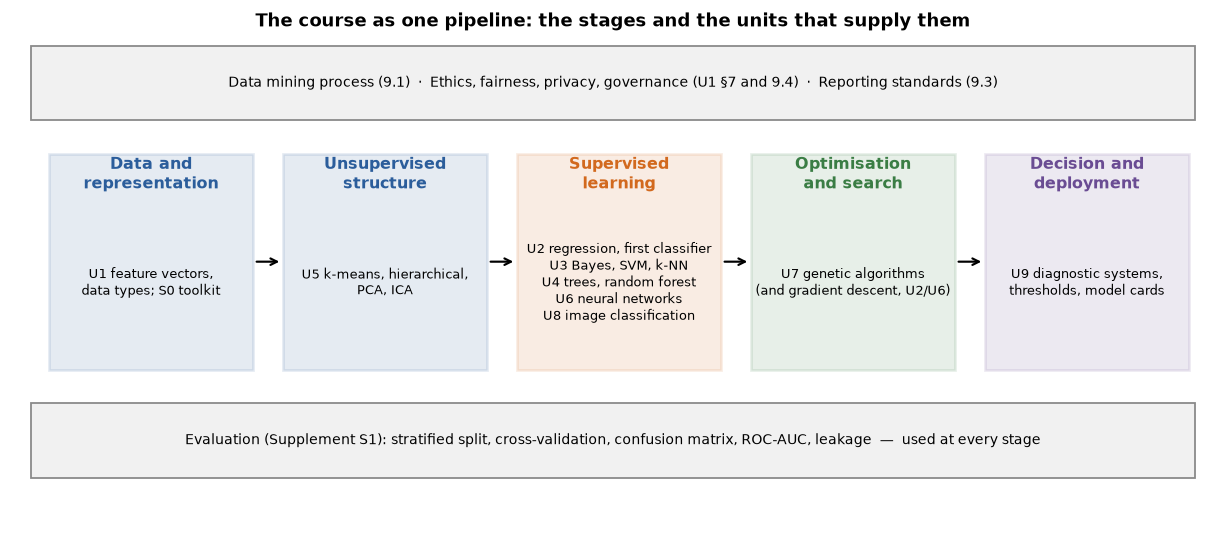

In [2]:
# Un mapa de una página del curso como un solo pipeline, con la unidad que aporta cada etapa.
stages = [("Data and\nrepresentation", "U1 feature vectors,\ndata types; S0 toolkit", BLUE),
          ("Unsupervised\nstructure", "U5 k-means, hierarchical,\nPCA, ICA", BLUE),
          ("Supervised\nlearning", "U2 regression, first classifier\nU3 Bayes, SVM, k-NN\nU4 trees, random forest\nU6 neural networks\nU8 image classification", ORANGE),
          ("Optimisation\nand search", "U7 genetic algorithms\n(and gradient descent, U2/U6)", GREEN),
          ("Decision and\ndeployment", "U9 diagnostic systems,\nthresholds, model cards", "#6a4c93")]
fig, ax = plt.subplots(figsize=(9.5, 4.3))
ax.set_xlim(0, 10); ax.set_ylim(0, 6); ax.axis("off")
for i, (title, body, col) in enumerate(stages):
    x = 0.3 + i * 1.95
    ax.add_patch(plt.Rectangle((x, 2.0), 1.7, 2.6, facecolor=col, alpha=0.12, edgecolor=col, lw=1.5))
    ax.text(x + 0.85, 4.35, title, ha="center", va="center", fontsize=9, fontweight="bold", color=col)
    ax.text(x + 0.85, 3.05, body, ha="center", va="center", fontsize=7.2)
    if i < len(stages) - 1:
        ax.annotate("", xy=(x + 1.95, 3.3), xytext=(x + 1.7, 3.3), arrowprops=dict(arrowstyle="->", color="k", lw=1.2))
# el marco: evaluación abajo, ética y gobernanza arriba
ax.add_patch(plt.Rectangle((0.15, 0.7), 9.7, 0.9, facecolor="#f1f1f1", edgecolor=GREY))
ax.text(5, 1.15, "Evaluation (Supplement S1): stratified split, cross-validation, confusion matrix, ROC-AUC, leakage  —  used at every stage", ha="center", va="center", fontsize=8)
ax.add_patch(plt.Rectangle((0.15, 5.0), 9.7, 0.9, facecolor="#f1f1f1", edgecolor=GREY))
ax.text(5, 5.45, "Data mining process (9.1)  ·  Ethics, fairness, privacy, governance (U1 §7 and 9.4)  ·  Reporting standards (9.3)", ha="center", va="center", fontsize=8)
ax.set_title("The course as one pipeline: the stages and the units that supply them")
fig.tight_layout()

<p class="caption"><b>Figura 1.</b> El curso como un solo pipeline: las cinco etapas con la unidad que estudió cada una, y las preocupaciones que se aplican en todas las etapas. La Sección 4.4 recorre la figura completa una vez sobre un solo conjunto de datos.</p>

Tres observaciones organizan la unidad. El pipeline se ejecuta muchas veces, no una sola —de ahí los modelos de proceso de la Sección 2—. Los métodos de las Unidades 2–7 son herramientas para distintas <em>tareas</em> (Sección 2.2). Y las Unidades 1–8 evaluaron los modelos frente a una etiqueta, mientras que esta unidad los evalúa frente a una <em>decisión</em> —ordenar una biopsia o no—, razón por la cual la calibración, las curvas de decisión y los costos dominan la Sección 4.

<div class="box bridge"><h4>Laboratorio 6 y Taller 6</h4><p>Para el Laboratorio 6, el proyecto integrador de la Sección 4.4 es la plantilla y la lista de verificación de la Sección 5.6 es la pauta de evaluación. Para el Taller 6, la Sección 6 enumera quince sistemas reales con su nivel de evidencia, y la Sección 3.3 explica cómo juzgarlo.</p></div>

## 2. Minería de datos (9.1)

### 2.1 Definición y el proceso KDD

Fayyad, Piatetsky-Shapiro y Smyth definieron el <em>descubrimiento de conocimiento en bases de datos</em> (knowledge discovery in databases, KDD) como "el proceso no trivial de identificar patrones válidos, novedosos, potencialmente útiles y, en última instancia, comprensibles en los datos"; la <strong>minería de datos</strong> es el paso en el que un algoritmo los extrae.<sup class="c"><a href="#r1">[1]</a></sup> Cada adjetivo es un requisito —válido en datos nuevos (S1), no conocido de antemano, relevante para la decisión, verificable— y la definición se anticipa en dos décadas a la Sección 5.

KDD recorre selección → preprocesamiento → transformación (Unidades 1, 5) → minería de datos (Unidades 2–7) → interpretación y evaluación, con bucles de retorno. La industria formalizó el ciclo en 2000 como <strong>CRISP-DM</strong>: comprensión del negocio, comprensión de los datos, preparación de los datos, modelado, evaluación, despliegue. Una revisión de 2021 encontró que sigue siendo el modelo de proceso más usado, por lo general con el despliegue omitido o apenas esbozado —con las consecuencias de la Sección 4.7—.<sup class="c"><a href="#r2">[2]</a></sup> Ambos modelos dicen lo mismo: la mayor parte del trabajo ocurre antes y después del algoritmo.

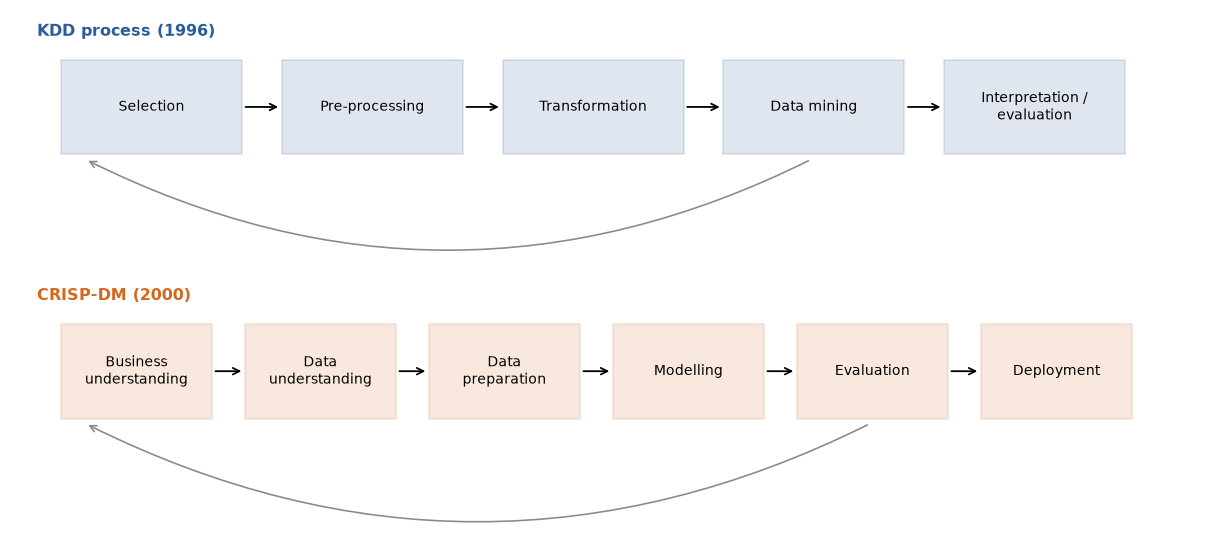

In [3]:
# Los dos modelos de proceso lado a lado: KDD (Fayyad et al. 1996) y CRISP-DM (2000). Las flechas marcan los bucles de retroalimentación.
kdd = ["Selection", "Pre-processing", "Transformation", "Data mining", "Interpretation /\nevaluation"]
crisp = ["Business\nunderstanding", "Data\nunderstanding", "Data\npreparation", "Modelling", "Evaluation", "Deployment"]
fig, axes = plt.subplots(2, 1, figsize=(9.5, 4.2))
for ax, steps, name, col in [(axes[0], kdd, "KDD process (1996)", BLUE), (axes[1], crisp, "CRISP-DM (2000)", ORANGE)]:
    ax.set_xlim(0, 10); ax.set_ylim(0, 2); ax.axis("off")
    w = 9.2 / len(steps)
    for i, s in enumerate(steps):
        x = 0.4 + i * w
        ax.add_patch(plt.Rectangle((x, 0.5), w * 0.82, 1.0, facecolor=col, alpha=0.15, edgecolor=col))
        ax.text(x + w * 0.41, 1.0, s, ha="center", va="center", fontsize=8)
        if i < len(steps) - 1:
            ax.annotate("", xy=(x + w, 1.0), xytext=(x + w * 0.82, 1.0), arrowprops=dict(arrowstyle="->", lw=1))
    # bucle de retroalimentación desde el paso de evaluación de vuelta al inicio
    ax.annotate("", xy=(0.6, 0.45), xytext=(0.4 + (len(steps) - 2) * w + w * 0.4, 0.45),
                arrowprops=dict(arrowstyle="->", lw=0.9, color=GREY, connectionstyle="arc3,rad=-0.25"))
    ax.set_ylim(-0.6, 2.0)
    ax.text(0.2, 1.75, name, fontsize=9, fontweight="bold", color=col)
fig.tight_layout()

<p class="caption"><b>Figura 2.</b> KDD y CRISP-DM. El paso algorítmico es una caja entre cinco o seis; las flechas grises son los bucles de retroalimentación. Solo CRISP-DM nombra el despliegue.</p>

### 2.2 Las cuatro familias de tareas, y dónde encajan las Unidades 2–7

Las tareas de minería de datos se agrupan por <em>pregunta</em>, no por algoritmo, y la primera decisión en cualquier proyecto es qué pregunta se plantea.

| Familia | Pregunta | Salida | Métodos en este curso |
|---|---|---|---|
| **Clasificación** | ¿A qué categoría pertenece este objeto? | Etiqueta de clase o probabilidad | U1 centroide más cercano; U2 regresión logística; U3 Bayes, k-NN, SVM; U4 árboles, bosques; U6 MLP; U8 clasificadores de imágenes |
| **Regresión** | ¿Qué valor de una cantidad continua se espera? | Un número | U2 lineal y polinomial; regresión con k-NN, SVM, árboles y MLP (U3, U4, U6) |
| **Agrupamiento (clustering)** | ¿Qué objetos se parecen entre sí? | Grupos encontrados sin etiquetas | U5 k-means, jerárquico, PCA, ICA |
| **Asociación** | ¿Qué eventos ocurren juntos? | Reglas "si A entonces B" con una fuerza | Reglas de asociación y Apriori — **solo en esta unidad** |

Transversalmente a las familias se ubican la <em>detección de anomalías</em> (Sección 2.7), la <em>optimización</em> (U7) y la <em>minería de texto</em> (Sección 2.8). Ninguna otra unidad aborda las reglas de asociación, por lo que esta sección las trata en profundidad.

<div class="box bridge"><h4>Puente con la bioinformática: la investigación del docente como minería de datos</h4><p>Dos artículos del laboratorio del curso son KDD aplicado a la química. Morales y colaboradores representaron inhibidores de ureasa y compuestos inactivos mediante descriptores fisicoquímicos, entrenaron clasificadores —entre ellos los ensambles de árboles de la Unidad 4— y derivaron <em>criterios de filtrado</em> que un químico puede aplicar antes de la síntesis.<sup class="c"><a href="#r8">[8]</a></sup> González y colaboradores hicieron lo mismo con inhibidores de TRPV1, agregaron un cribado de reposicionamiento de fármacos aprobados y validaron los candidatos mediante docking y simulación de dinámica molecular.<sup class="c"><a href="#r9">[9]</a></sup> Los objetos son moléculas, las características son descriptores, la etiqueta es la actividad y el "despliegue" es la elección de los compuestos que se van a ensayar: los modelos QSAR de BGM324 vistos como reconocimiento de patrones.</p></div>

### 2.3 Reglas de asociación: soporte, confianza, lift

Agrawal, Imieliński y Swami introdujeron las reglas de asociación en 1993 para el problema de la <em>canasta de mercado</em> (market basket).<sup class="c"><a href="#r3">[3]</a></sup> En salud, la canasta es un paciente, los ítems son diagnósticos, medicamentos o alteraciones de laboratorio, y las reglas son patrones de comorbilidad y de prescripción o candidatas a reacciones adversas. Sea $D$ una base de datos de $N$ <strong>transacciones</strong>, cada una un subconjunto de los ítems $I$; un <strong>conjunto de ítems</strong> (itemset) es cualquier subconjunto de $I$ y una <strong>regla</strong> $A \Rightarrow B$ es una implicación entre conjuntos de ítems disjuntos. Tres cantidades describen una regla:

<div class="eq">$$\text{supp}(A) = \frac{|\{T \in D : A \subseteq T\}|}{N}, \qquad \text{conf}(A \Rightarrow B) = \frac{\text{supp}(A \cup B)}{\text{supp}(A)}, \qquad \text{lift}(A \Rightarrow B) = \frac{\text{conf}(A \Rightarrow B)}{\text{supp}(B)} = \frac{\text{supp}(A \cup B)}{\text{supp}(A)\,\text{supp}(B)}$$
<span class="where">El soporte estima $P(A)$ (para una regla, $\text{supp}(A \cup B)$); la confianza estima $P(B \mid A)$; el lift es $P(A, B)/(P(A)P(B))$ — 1 bajo independencia.</span></div>

La confianza por sí sola engaña: si el 90 % de los pacientes toma paracetamol, "hipertensión ⇒ paracetamol" tiene confianza 0.9 y no dice nada. Brin, Motwani y Silverstein mostraron en 1997 que la confianza puede ordenar las reglas en el orden inverso al de su dependencia y propusieron medir, en cambio, el alejamiento de la independencia —el lift (<em>interés</em>) y, como prueba formal, el estadístico chi-cuadrado de la Sección 2.6—.<sup class="c"><a href="#r5">[5]</a></sup>

### 2.4 El algoritmo Apriori, a mano

Hay $2^{|I|}$ conjuntos de ítems, de modo que enumerarlos es imposible. El algoritmo <strong>Apriori</strong> de Agrawal y Srikant (1994) aprovecha la propiedad de <em>clausura descendente</em> (downward closure): <strong>todo subconjunto de un conjunto de ítems frecuente es frecuente</strong>, por lo que un conjunto de ítems solo puede ser frecuente si todos sus subconjuntos lo son.<sup class="c"><a href="#r4">[4]</a></sup> Nivel a nivel: (1) conservar los ítems individuales por encima del soporte mínimo, $L_1$; (2) <strong>unir</strong> (join) pares de $(k-1)$-conjuntos frecuentes que comparten sus primeros $k-2$ ítems para formar los candidatos $C_k$; (3) <strong>podar</strong> (prune) los candidatos que tengan un $(k-1)$-subconjunto que no esté en $L_{k-1}$; (4) contar los sobrevivientes en una pasada, lo que da $L_k$; repetir hasta que quede vacío; (5) entregar cada partición $A \Rightarrow B$ de un conjunto de ítems frecuente cuya confianza supere un mínimo, junto con su lift.

**Ejemplo resuelto.** Seis pacientes, cinco ítems en el orden HTN < DM < Met < ACEi < Statin (hipertensión, diabetes tipo 2, metformina, inhibidor de la ECA, estatina); soporte mínimo 2 de 6.

| paciente | ítems |
|---|---|
| 1 | HTN, DM, Met, Statin |
| 2 | HTN, ACEi |
| 3 | DM, Met |
| 4 | HTN, DM, Met, ACEi |
| 5 | HTN, Statin |
| 6 | DM, Met, Statin |

**Nivel 1.** HTN 4, DM 4, Met 4, ACEi 2, Statin 3 — los cinco son frecuentes. **Nivel 2.** La unión entrega los $\binom{5}{2} = 10$ pares (no hay nada que podar, pues todo 1-subconjunto es frecuente):

| par | pacientes | conteo | ¿frecuente? |
|---|---|---|---|
| HTN, DM | 1, 4 | 2 | sí |
| HTN, Met | 1, 4 | 2 | sí |
| HTN, ACEi | 2, 4 | 2 | sí |
| HTN, Statin | 1, 5 | 2 | sí |
| DM, Met | 1, 3, 4, 6 | 4 | sí |
| DM, ACEi | 4 | 1 | no |
| DM, Statin | 1, 6 | 2 | sí |
| Met, ACEi | 4 | 1 | no |
| Met, Statin | 1, 6 | 2 | sí |
| ACEi, Statin | — | 0 | no |

**Nivel 3, unión:** los pares de $L_2$ con el mismo primer ítem entregan siete candidatos — {HTN, DM, Met}, {HTN, DM, ACEi}, {HTN, DM, Statin}, {HTN, Met, ACEi}, {HTN, Met, Statin}, {HTN, ACEi, Statin} y {DM, Met, Statin}. **Poda:** {HTN, DM, ACEi} contiene el no frecuente {DM, ACEi}; {HTN, Met, ACEi} contiene {Met, ACEi}; {HTN, ACEi, Statin} contiene {ACEi, Statin} — tres podados sin contar. **Conteo** de los cuatro sobrevivientes: {HTN, DM, Met} en los pacientes 1 y 4 (frecuente); {HTN, DM, Statin} y {HTN, Met, Statin} solo en el paciente 1 (no frecuentes); {DM, Met, Statin} en 1 y 6 (frecuente). $L_3$ tiene dos conjuntos de ítems que no comparten un prefijo de 2 ítems, de modo que $C_4$ queda vacío y el algoritmo se detiene. **Reglas:** DM ⇒ Met tiene soporte 4/6 = 0.67, confianza 4/4 = 1.00 y lift 1.00/(4/6) = 1.50; HTN ⇒ Statin tiene confianza 2/4 = 0.50 y lift 0.50/(3/6) = 1.00 — el mismo soporte que varias otras y ninguna asociación en absoluto. La celda siguiente reproduce la traza.

In [4]:
# Apriori en el ejemplo de seis pacientes: conjuntos de ítems frecuentes nivel a nivel, con los pasos de unión y poda explícitos.
from itertools import combinations
toy = pd.DataFrame([[1, 1, 1, 0, 1], [1, 0, 0, 1, 0], [0, 1, 1, 0, 0], [1, 1, 1, 1, 0], [1, 0, 0, 0, 1], [0, 1, 1, 0, 1]],
                   columns=["HTN", "DM", "Met", "ACEi", "Statin"], index=[f"patient {i}" for i in range(1, 7)]).astype(bool)

def apriori(df, min_support, verbose=False):
    '''Frequent itemsets of a boolean transaction table. Returns {frozenset: support} and the number of candidates per level.'''
    M, items, n = df.to_numpy(), list(df.columns), len(df)
    support, counted = {}, {}
    L = [(it,) for j, it in enumerate(items) if M[:, j].mean() >= min_support]       # nivel 1
    support.update({frozenset(c): M[:, items.index(c[0])].mean() for c in L})
    k = 1
    while L:
        k += 1; Lset = set(L); C = set()
        for a in L:                                                                   # paso de unión: prefijo común de (k-2) ítems
            for b in L:
                if a[:-1] == b[:-1] and items.index(a[-1]) < items.index(b[-1]):
                    c = a + (b[-1],)
                    if all(tuple(x for x in c if x != d) in Lset for d in c):         # paso de poda: todos los subconjuntos frecuentes
                        C.add(c)
        counted[k] = len(C); newL = []
        for c in sorted(C, key=lambda c: [items.index(x) for x in c]):
            s = M[:, [items.index(x) for x in c]].all(axis=1).mean()
            if verbose: print(f"  L{k} candidate {set(c)}: support {s:.2f} -> {'frequent' if s >= min_support else 'discarded'}")
            if s >= min_support: support[frozenset(c)] = s; newL.append(c)
        L = newL
    return support, counted

supp_toy, counted_toy = apriori(toy, 2 / 6)
print("Level 1 supports:", {next(iter(k)): round(v, 2) for k, v in supp_toy.items() if len(k) == 1})
supp_toy, counted_toy = apriori(toy, 2 / 6, verbose=True)
print("candidates counted per level:", counted_toy, "| frequent itemsets with 3 items:", [set(s) for s in supp_toy if len(s) == 3])

Level 1 supports: {'HTN': np.float64(0.67), 'DM': np.float64(0.67), 'Met': np.float64(0.67), 'ACEi': np.float64(0.33), 'Statin': np.float64(0.5)}
  L2 candidate {'HTN', 'DM'}: support 0.33 -> frequent
  L2 candidate {'HTN', 'Met'}: support 0.33 -> frequent
  L2 candidate {'ACEi', 'HTN'}: support 0.33 -> frequent
  L2 candidate {'HTN', 'Statin'}: support 0.33 -> frequent
  L2 candidate {'DM', 'Met'}: support 0.67 -> frequent
  L2 candidate {'ACEi', 'DM'}: support 0.17 -> discarded
  L2 candidate {'DM', 'Statin'}: support 0.33 -> frequent
  L2 candidate {'ACEi', 'Met'}: support 0.17 -> discarded
  L2 candidate {'Met', 'Statin'}: support 0.33 -> frequent
  L2 candidate {'ACEi', 'Statin'}: support 0.00 -> discarded
  L3 candidate {'HTN', 'DM', 'Met'}: support 0.33 -> frequent
  L3 candidate {'HTN', 'Statin', 'DM'}: support 0.17 -> discarded
  L3 candidate {'HTN', 'Statin', 'Met'}: support 0.17 -> discarded
  L3 candidate {'DM', 'Statin', 'Met'}: support 0.33 -> frequent
candidates counted 

In [5]:
# Reglas a partir de los conjuntos de ítems frecuentes: soporte, confianza y lift de cada partición A => B.
def rules_from(support, min_conf=0.0):
    '''Enumerate rules A => B over all frequent itemsets with at least two items.'''
    rows = []
    for S, s in support.items():
        if len(S) < 2: continue
        for r in range(1, len(S)):
            for A in combinations(sorted(S), r):
                A = frozenset(A); B = S - A
                conf = s / support[A]
                rows.append({"antecedent": " & ".join(sorted(A)), "consequent": " & ".join(sorted(B)),
                             "support": s, "confidence": conf, "lift": conf / support[B]})
    out = pd.DataFrame(rows)
    return out[out.confidence >= min_conf].sort_values("lift", ascending=False).reset_index(drop=True)

toy_rules = rules_from(supp_toy)
print(f"{len(toy_rules)} rules from {sum(len(S) >= 2 for S in supp_toy)} frequent itemsets with 2+ items")
toy_rules[toy_rules.antecedent.isin(["DM", "HTN"]) & toy_rules.consequent.isin(["Met", "Statin"])].round(2)

26 rules from 9 frequent itemsets with 2+ items


,antecedent,consequent,support,confidence,lift
6,DM,Met,0.67,1.0,1.50
17,DM,Statin,0.33,0.5,1.00
19,HTN,Statin,0.33,0.5,1.00
24,HTN,Met,0.33,0.5,0.75


La traza coincide con el cálculo a mano: cuatro de siete candidatos de nivel 3 contados, dos 3-conjuntos frecuentes, DM ⇒ Met con lift 1.50 frente a HTN ⇒ Statin con lift 1.00. El mismo código funciona sin cambios sobre la tabla de 1,500 pacientes de más abajo.

<div class="exercise"><h4>Ejercicio 1</h4><p>Baja el soporte mínimo a 1/6 y vuelve a ejecutar ambas celdas: ¿cuántos candidatos de nivel 3 se cuentan ahora y cuántas reglas resultan? Luego agrega un séptimo paciente con los ítems {ACEi, Statin} con soporte 2/6: ¿qué candidato de nivel 3 antes podado se cuenta ahora, y llega a ser frecuente?</p></div>

### 2.5 Apriori sobre una base de datos clínica sintética

Los registros reales no pueden distribuirse junto con un notebook, así que la celda siguiente genera 1,500 pacientes con siete comorbilidades y ocho medicamentos, sembrando asociaciones plausibles —metformina para los diabéticos, inhibidores de la ECA para los hipertensos, estatinas para ambos, salbutamol para la EPOC, ISRS para la depresión, betabloqueadores para la insuficiencia cardíaca, la obesidad que aumenta la diabetes y la hipertensión que aumenta la insuficiencia cardíaca— y dejando todo lo demás independiente, para poder ver qué reglas recupera el minero y cuáles inventa.

In [6]:
# Un 'registro electrónico' sintético de 1,500 pacientes: comorbilidades y medicamentos con asociaciones sembradas.
rng = np.random.default_rng(0); n_pat = 1500
def bern(p, size=n_pat): return rng.random(size) < p
htn, obes, copd, dep, ckd = bern(0.45), bern(0.30), bern(0.12), bern(0.15), bern(0.08)
dm = bern(0.25) | (obes & bern(0.25))                      # la obesidad aumenta la probabilidad de diabetes
hf = bern(0.10) | (htn & bern(0.10))                        # la hipertensión aumenta la probabilidad de insuficiencia cardíaca
def prescribed(condition, p_if, p_else):
    '''A drug given with probability p_if when the condition is present, p_else otherwise.'''
    return np.where(condition, bern(p_if), bern(p_else))
records = pd.DataFrame({
    "hypertension": htn, "type2_diabetes": dm, "obesity": obes, "COPD": copd, "heart_failure": hf, "depression": dep, "CKD": ckd,
    "metformin": prescribed(dm, 0.75, 0.02), "insulin": prescribed(dm, 0.25, 0.01), "ACE_inhibitor": prescribed(htn, 0.55, 0.05),
    "beta_blocker": prescribed(hf, 0.70, 0.08), "statin": prescribed(dm & htn, 0.70, 0.0) | prescribed(dm | htn, 0.35, 0.08),
    "salbutamol": prescribed(copd, 0.65, 0.04), "SSRI": prescribed(dep, 0.60, 0.03), "aspirin": prescribed(hf | htn, 0.30, 0.10)})
print(f"{records.shape[0]} patients x {records.shape[1]} items; items per patient: median {records.sum(axis=1).median():.0f}, max {records.sum(axis=1).max()}")
print("item support (fraction of patients):")
print(records.mean().round(3).sort_values(ascending=False).to_string())

1500 patients x 15 items; items per patient: median 3, max 11
item support (fraction of patients):
hypertension      0.435
statin            0.311
obesity           0.307
type2_diabetes    0.302
ACE_inhibitor     0.252
metformin         0.239
aspirin           0.187
beta_blocker      0.171
depression        0.159
heart_failure     0.145
COPD              0.119
SSRI              0.114
salbutamol        0.107
CKD               0.086
insulin           0.085


In [7]:
# Apriori con soporte mínimo 0.05, luego las reglas con confianza >= 0.5, ordenadas por lift.
t0 = time.perf_counter()
supp_rec, counted_rec = apriori(records, min_support=0.05)
by_level = pd.Series({k: sum(len(S) == k for S in supp_rec) for k in range(1, 6)}, name="frequent itemsets")
print(f"{time.perf_counter() - t0:.2f} s | frequent itemsets per level: {by_level.to_dict()} | candidates counted: {counted_rec}")
rec_rules = rules_from(supp_rec, min_conf=0.5)
print(f"{len(rec_rules)} rules with confidence >= 0.5; the 12 with the highest lift:")
rec_rules.head(12).round(3)

0.00 s | frequent itemsets per level: {1: 15, 2: 38, 3: 20, 4: 5, 5: 0} | candidates counted: {2: 105, 3: 50, 4: 5, 5: 0}
89 rules with confidence >= 0.5; the 12 with the highest lift:


,antecedent,consequent,support,confidence,lift
0,ACE_inhibitor & metformin,hypertension & type2_diabetes,0.053,0.842,6.044
1,hypertension & metformin,ACE_inhibitor & type2_diabetes,0.053,0.500,5.906
2,ACE_inhibitor & type2_diabetes,hypertension & metformin,0.053,0.630,5.906
3,COPD,salbutamol,0.069,0.579,5.425
4,salbutamol,COPD,0.069,0.644,5.425
5,depression,SSRI,0.089,0.563,4.939
6,SSRI,depression,0.089,0.784,4.939
7,beta_blocker & hypertension,heart_failure,0.067,0.697,4.793
8,metformin & statin,hypertension & type2_diabetes,0.081,0.635,4.560
9,hypertension & type2_diabetes,metformin & statin,0.081,0.584,4.560


El minero recupera la estructura sembrada: los lifts más altos, de alrededor de 4 a 5.5, corresponden a los pares fármaco–indicación (EPOC ⇔ salbutamol, depresión ⇔ ISRS, insuficiencia cardíaca ⇔ betabloqueador) y a reglas compuestas sobre hipertensión, diabetes, metformina, inhibidor de la ECA y estatina, cuyos consecuentes de dos ítems son poco frecuentes. Cada asociación aparece en ambas direcciones con igual soporte y lift pero distinta confianza —"SSRI ⇒ depression" tiene más confianza que "depression ⇒ SSRI" porque no todo paciente deprimido recibe tratamiento, pero casi todo usuario de ISRS está deprimido—; el lift es simétrico, la confianza no lo es, y ninguno de los dos es causal. Las reglas sobre conjuntos de ítems compuestos son redundantes con las reglas por pares que las componen.

### 2.6 La trampa: reglas espurias y comparaciones múltiples

Un minero pone a prueba cada par y cada conjunto de ítems mayor: 105 pares para 15 ítems, más de un millón para 1,500 códigos CIE-10. Algunos tendrán un lift muy por encima de 1 por azar, y el minero, que no tiene hipótesis nula, los informa junto a los reales. La celda cuantifica esto <em>destruyendo todas las asociaciones</em> —permutando cada columna de forma independiente, lo que conserva las frecuencias de los ítems pero hace que cada ítem sea independiente de todos los demás— y minando la tabla permutada con un soporte mínimo más bajo, donde los pares poco frecuentes son ruidosos.

real table: 79 pairwise rules, 21 with lift > 1.3, maximum lift 5.42
50 shuffled tables: maximum pairwise lift per table ranges 1.15-1.65; 1.6% of null rules have lift > 1.3


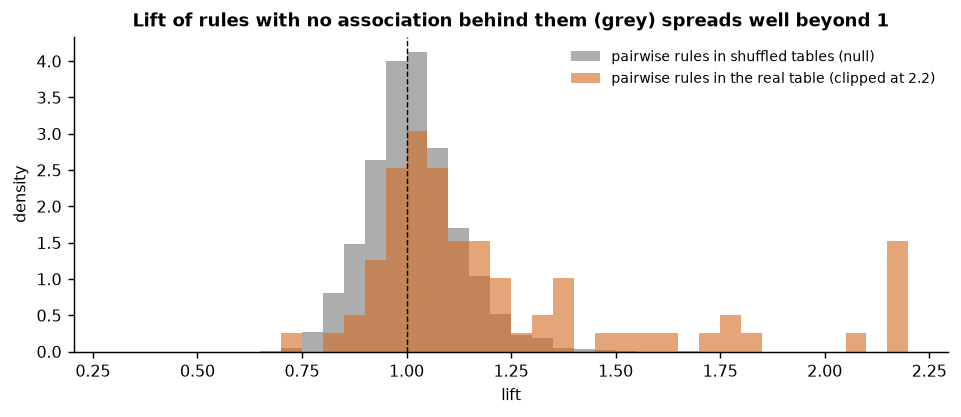

In [8]:
# Nula por permutación: barajar cada columna de forma independiente (asociaciones destruidas, frecuencias conservadas) y minar de nuevo.
def pairwise(rule_table):
    '''Keep only single-item => single-item rules, one direction each (lift is symmetric).'''
    r = rule_table[~rule_table.antecedent.str.contains("&") & ~rule_table.consequent.str.contains("&")]
    return r[r.antecedent < r.consequent]
real_pairs = pairwise(rules_from(apriori(records, 0.02)[0]))
null_max = []; null_lifts = []
for rep in range(50):
    shuffled = records.apply(lambda col: rng.permutation(col.to_numpy()))
    pairs = pairwise(rules_from(apriori(shuffled, 0.02)[0]))
    null_lifts.append(pairs.lift.to_numpy()); null_max.append(pairs.lift.max())
null_lifts = np.concatenate(null_lifts)
print(f"real table: {len(real_pairs)} pairwise rules, {int((real_pairs.lift > 1.3).sum())} with lift > 1.3, maximum lift {real_pairs.lift.max():.2f}")
print(f"50 shuffled tables: maximum pairwise lift per table ranges {min(null_max):.2f}-{max(null_max):.2f}; "
      f"{(null_lifts > 1.3).mean():.1%} of null rules have lift > 1.3")

fig, ax = plt.subplots(figsize=(7.5, 3.3))
bins = np.linspace(0.3, 2.2, 39)
ax.hist(null_lifts, bins=bins, density=True, color=GREY, alpha=0.7, label="pairwise rules in shuffled tables (null)")
ax.hist(real_pairs.lift.clip(upper=2.2), bins=bins, density=True, color=ORANGE, alpha=0.6, label="pairwise rules in the real table (clipped at 2.2)")
ax.axvline(1, color="k", lw=0.8, ls="--"); ax.set_xlabel("lift"); ax.set_ylabel("density"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Lift of rules with no association behind them (grey) spreads well beyond 1")
fig.tight_layout()

<p class="caption"><b>Figura 3.</b> Lift de las reglas por pares de 50 copias barajadas de la tabla (gris; toda asociación destruida) frente a la tabla real (naranja; lifts sembrados de hasta alrededor de 5, recortados en 2.2). La distribución nula está centrada en 1 pero alcanza 1.5 y más: quien informa cada regla con lift superior a 1.3 informa reglas de la distribución gris.</p>

El remedio es el de la Unidad 3 y del Suplemento S1: tratar cada regla como una prueba de hipótesis —para un par, la prueba chi-cuadrado de independencia sobre su tabla de 2 × 2— y corregir por las $m$ pruebas realizadas, con <strong>Bonferroni</strong> ($p < \alpha/m$) o con la tasa de falsos descubrimientos de Benjamini–Hochberg. La celda siguiente lo hace para las reglas por pares de la tabla real.

In [9]:
# Prueba chi-cuadrado de independencia para cada regla por pares, con y sin corrección de Bonferroni.
from scipy.stats import chi2_contingency
def chi2_p(a, b):
    return chi2_contingency(pd.crosstab(records[a], records[b]))[1]
tested = real_pairs.assign(p_value=[chi2_p(a, b) for a, b in zip(real_pairs.antecedent, real_pairs.consequent)])
m = len(tested)
tested["significant_0.05"] = tested.p_value < 0.05
tested["significant_Bonferroni"] = tested.p_value < 0.05 / m
print(f"{m} pairwise rules tested | p < 0.05: {tested['significant_0.05'].sum()} | Bonferroni p < 0.05/{m}: {tested['significant_Bonferroni'].sum()}")
print("Rules with lift between 1.1 and 1.6 - the region where real and spurious overlap:")
tested[(tested.lift > 1.1) & (tested.lift < 1.6)].sort_values("lift", ascending=False).round(4).head(8)

79 pairwise rules tested | p < 0.05: 25 | Bonferroni p < 0.05/79: 18
Rules with lift between 1.1 and 1.6 - the region where real and spurious overlap:


,antecedent,consequent,support,confidence,lift,p_value,significant_0.05,significant_Bonferroni
1056,heart_failure,hypertension,0.0987,0.6789,1.5595,0.0000,True,True
1109,aspirin,hypertension,0.1227,0.6571,1.5095,0.0000,True,True
1151,ACE_inhibitor,statin,0.1153,0.4577,1.4700,0.0000,True,True
1226,ACE_inhibitor,heart_failure,0.0500,0.1984,1.3652,0.0010,True,False
1234,ACE_inhibitor,COPD,0.0407,0.1614,1.3599,0.0040,True,False
1237,insulin,obesity,0.0353,0.4173,1.3579,0.0068,True,False
1241,metformin,obesity,0.0993,0.4150,1.3505,0.0000,True,True
1248,obesity,type2_diabetes,0.1240,0.4035,1.3360,0.0000,True,True


Las reglas sembradas sobreviven con valores $p$ que son numéricamente cero. La región de solapamiento (lifts de 1.1–1.6) es una mezcla —obesidad ⇒ diabetes fue sembrada; metformina ⇒ obesidad e insulina ⇒ obesidad pasan a través de la diabetes; insuficiencia cardíaca ⇒ hipertensión y aspirina ⇒ hipertensión se derivan de dependencias sembradas; inhibidor de la ECA ⇒ EPOC es azar— y la prueba separa la mayoría de ellas: la regla debida al azar y las indirectas más débiles pasan el umbral de 0.05 y no superan Bonferroni. Quedan tres límites: una asociación real puede ser trivial; puede estar <em>confundida</em>, como lo está metformina ⇒ obesidad; y ninguna regla es causal —la minería genera hipótesis que los diseños epidemiológicos ponen a prueba—. La farmacovigilancia usa exactamente este pipeline: medidas de desproporcionalidad, tamizaje estadístico, revisión clínica.

<div class="box warn"><h4>El efecto de mirar en otra parte (look-elsewhere effect)</h4><p>Todo método que <em>busca</em> —reglas, anomalías, subgrupos (Sección 5.2), importancias de características (Sección 5.3)— pone a prueba muchas hipótesis a la vez, y el máximo de muchas estimaciones ruidosas está sesgado hacia arriba, como mostró S1 para la selección de hiperparámetros. Toda cantidad seleccionada por ser la mayor debe volver a estimarse con datos que no participaron en la selección.</p></div>

### 2.7 La detección de anomalías en una celda

La detección de anomalías pregunta <em>¿qué objetos no se parecen al resto?</em> y no necesita etiquetas —es la pregunta para fallas de equipos, reclamos fraudulentos, valores de laboratorio de una enfermedad no reconocida o errores de digitación—. El <strong>bosque de aislamiento</strong> (isolation forest) de Liu, Ting y Zhou reutiliza los árboles de la Unidad 4: divisiones aleatorias hasta que cada punto queda aislado, y el <em>número de divisiones necesarias</em> es el puntaje —las anomalías, pocas y diferentes, se aíslan rápidamente—.<sup class="c"><a href="#r6">[6]</a></sup> La celda entrena solo con los casos <em>benignos</em> de Wisconsin, como si la malignidad fuera una condición nunca vista, y pregunta si los casos malignos quedan marcados.

trained on 357 benign cases | AUC of the anomaly score for malignancy: 0.962
flagged as anomalous: 87.7% of malignant cases, 8.7% of benign cases


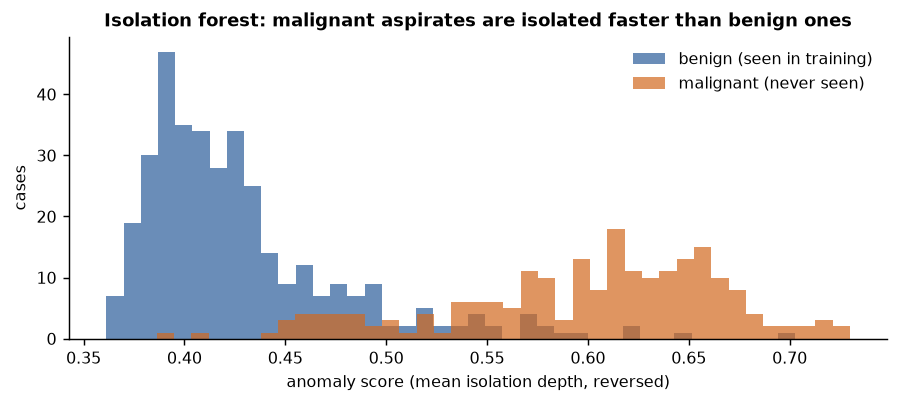

In [10]:
# Bosque de aislamiento entrenado solo con aspirados benignos; ¿los malignos parecen anómalos?
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score
cancer = datasets.load_breast_cancer(as_frame=True)
Xc, yc = cancer.data, (cancer.target == 0).astype(int)                    # yc: 1 = maligno (la codificación de 'enfermedad' usada en todo el notebook)
benign_only = Xc[yc == 0]
iso = IsolationForest(n_estimators=300, contamination="auto", random_state=0).fit(benign_only)
score = -iso.score_samples(Xc)                                            # mayor = más anómalo
auc_anom = roc_auc_score(yc, score)
flag = iso.predict(Xc) == -1
print(f"trained on {len(benign_only)} benign cases | AUC of the anomaly score for malignancy: {auc_anom:.3f}")
print(f"flagged as anomalous: {flag[yc == 1].mean():.1%} of malignant cases, {flag[yc == 0].mean():.1%} of benign cases")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(score[yc == 0], bins=40, alpha=0.7, color=BLUE, label="benign (seen in training)")
ax.hist(score[yc == 1], bins=40, alpha=0.7, color=ORANGE, label="malignant (never seen)")
ax.set_xlabel("anomaly score (mean isolation depth, reversed)"); ax.set_ylabel("cases"); ax.legend(frameon=False)
ax.set_title("Isolation forest: malignant aspirates are isolated faster than benign ones")
fig.tight_layout()

<p class="caption"><b>Figura 4.</b> Puntajes de anomalía de los 569 aspirados según un bosque de aislamiento que vio solo casos benignos. Los casos malignos (naranja) se aíslan con menos divisiones y el puntaje alcanza el AUC impreso arriba (alrededor de 0.96) sin una sola etiqueta maligna —con un solapamiento considerable—: la detección de anomalías encuentra lo que es <em>diferente</em>, no lo que está <em>enfermo</em>.</p>

Un modelo supervisado sobre los mismos datos alcanza un AUC cercano a 0.99 (Unidad 3, Sección 8), de modo que el precio de no tener etiquetas es real, y un detector también marca fallas del instrumento y condiciones benignas poco frecuentes. Su papel es el tamizaje de lo inesperado y el control de calidad; su salida es una lista ordenada para un humano, no un diagnóstico.

### 2.8 La minería de texto en un párrafo

La mayor parte de la información clínica es texto libre. La manera más simple de llevarla a la matriz de datos de la Unidad 1 es la <strong>bolsa de palabras</strong> (bag of words): cada documento se convierte en un vector de conteos de palabras sobre un vocabulario compartido, ignorando el orden; luego vienen Bayes ingenuo, SVM o agrupamiento. La representación no sabe que "sin fiebre" niega "fiebre" ni que "IAM" es "infarto agudo de miocardio"; el procesamiento de lenguaje natural clínico consiste en gran medida en reparar esos defectos —detección de negaciones, expansión de abreviaturas, mapeo a SNOMED CT, representaciones contextuales (embeddings) de modelos de lenguaje—. Una revisión de 263 estudios de extracción de información clínica encontró que los métodos de bolsa de palabras y los basados en reglas seguían dominando, que la mayoría de los sistemas eran de una sola institución y que pocos tenían validación externa.<sup class="c"><a href="#r7">[7]</a></sup> La celda muestra la idea con seis oraciones sintéticas.

In [11]:
# Bolsa de palabras: seis notas clínicas sintéticas se convierten en una matriz de conteos de 6 x |vocabulario|; un clasificador Bayes ingenuo aprende de ella.
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
notes = ["patient reports chest pain on exertion and shortness of breath",
         "productive cough for three weeks with fever and night sweats",
         "chest pain radiating to left arm, diaphoresis, nausea",
         "persistent cough, wheeze, history of smoking, no fever",
         "exertional chest tightness relieved by rest",
         "cough with fever and pleuritic chest pain"]
label = ["cardiac", "respiratory", "cardiac", "respiratory", "cardiac", "respiratory"]
vec = CountVectorizer(stop_words="english")
counts = vec.fit_transform(notes)
bow = pd.DataFrame(counts.toarray(), columns=vec.get_feature_names_out(), index=[f"note {i+1} ({l})" for i, l in enumerate(label)])
print(f"vocabulary of {len(vec.vocabulary_)} words (stop-words removed); matrix {bow.shape}")
nb = MultinomialNB().fit(counts, label)
new_note = ["sudden chest pain with sweating"]
print("new note:", new_note[0], "->", nb.predict(vec.transform(new_note))[0],
      "| P(cardiac) =", nb.predict_proba(vec.transform(new_note))[0][list(nb.classes_).index("cardiac")].round(2))
bow.loc[:, ["chest", "pain", "cough", "fever", "exertion", "sweats"]]

vocabulary of 27 words (stop-words removed); matrix (6, 27)
new note: sudden chest pain with sweating -> cardiac | P(cardiac) = 0.73


,chest,pain,cough,fever,exertion,sweats
note 1 (cardiac),1,1,0,0,1,0
note 2 (respiratory),0,0,1,1,0,1
note 3 (cardiac),1,1,0,0,0,0
note 4 (respiratory),0,0,1,1,0,0
note 5 (cardiac),1,0,0,0,0,0
note 6 (respiratory),1,1,1,1,0,0


Seis oraciones se convirtieron en una matriz de conteos sobre 27 palabras, y el Bayes ingenuo multinomial de la Unidad 3 aprendió que "chest" y "pain" apuntan a una nota cardíaca y que "cough" y "fever" apuntan a una respiratoria. La falla ya es visible: la nota 6 contiene "chest pain" (pleurítico, respiratorio) y la nota 4 un "fever" negado, y sin embargo ambos cuentan como presentes. El clasificador es un juguete; la representación es la que usó a gran escala la primera generación del NLP clínico, con estos límites.

<div class="exercise"><h4>Ejercicio 2</h4><p>Agrega dos notas que usen negación ("no chest pain", "denies fever") con etiquetas apropiadas y vuelve a ejecutar: ¿cambia la predicción para la nota nueva? Luego usa <code>CountVectorizer(ngram_range=(1, 2))</code> para que pares de palabras como "no fever" se conviertan en características, e inspecciona el vocabulario. ¿Cuánto cuesta esta corrección en número de características?</p></div>

## 3. Reconocimiento de imágenes médicas (9.2)

La Unidad 8 hizo el trabajo técnico de esta subunidad; esta sección es una síntesis: las tareas, por qué las imágenes médicas son difíciles, cómo se mide una segmentación, qué dice la evidencia.

### 3.1 La taxonomía de tareas

| Tarea | Entrada → salida | Ejemplo clínico | Métrica típica |
|---|---|---|---|
| **Clasificación** | Imagen completa → etiqueta o probabilidad | Retinopatía diabética referible a partir de una fotografía de fondo de ojo; lesión cutánea maligna vs benigna | Sensibilidad, especificidad, ROC-AUC (S1) |
| **Detección** | Imagen → cajas delimitadoras o puntos | Nódulos pulmonares en TC; microcalcificaciones en una mamografía | Sensibilidad a un número dado de falsos positivos por imagen |
| **Segmentación** | Imagen → una etiqueta por píxel/vóxel | Volumen tumoral en RM; contorno ventricular; núcleos en histología | Dice, IoU (Sección 3.4) |
| **Registro** | Dos imágenes → transformación de alineamiento | Exámenes pre y postoperatorios; etiquetado con atlas; corrección de movimiento | Error de registro del objetivo (mm) |
| **Reconstrucción** | Datos crudos o degradados → imagen | RM submuestreada; eliminación de ruido en TC de baja dosis | SNR, similitud estructural |

Los datos de Wisconsin se sitúan aguas arriba de las cinco: sus 30 características se extrajeron de núcleos previamente <em>segmentados</em> en una imagen de citología.

### 3.2 Qué hace diferentes a las imágenes médicas

El aprendizaje profundo para imágenes se desarrolló sobre ImageNet: 1.2 millones de fotografías con etiquetas que cualquiera puede aportar. Las imágenes médicas difieren en todos los aspectos, y cada diferencia es un modo de falla de un método transferido ingenuamente: **conjuntos de datos pequeños** (las redes se sobreajustan; el aprendizaje por transferencia y el aumento de datos, Unidad 8, son remedios parciales); **etiquetas escasas y ruidosas** (el tiempo de un radiólogo, una biopsia, un desenlace años después; el desacuerdo entre lectores le da a la verdad de referencia su propia tasa de error); **tres y cuatro dimensiones** (muchos datos por caso, pocos casos); **desbalance de clases** (prevalencia en tamizaje inferior al 1 %, donde la exactitud carece de sentido); **cambio de dominio** (fabricante, protocolo, población — Sección 3.5); **señal sutil y local** (unas pocas docenas de píxeles entre megapíxeles); **alto riesgo** (el clínico debe poder verificar la salida — Sección 5.3).

### 3.3 La base de evidencia

Liu y colaboradores agruparon 82 estudios que comparaban el aprendizaje profundo con profesionales de la salud sobre las mismas imágenes: sensibilidad agrupada de alrededor del 87 % y especificidad de alrededor del 93 % para los modelos, frente a 86 % y 91 % para los clínicos —equivalencia en promedio—, pero solo 25 estudios validaron fuera de la muestra y solo 14 compararon a ambos sobre la misma muestra externa.<sup class="c"><a href="#r10">[10]</a></sup> Nagendran y colaboradores examinaron el diseño: de 81 estudios no aleatorizados, pocos eran prospectivos, la mayoría comparaba el modelo con un puñado de clínicos que leían imágenes aisladas, los datos y el código rara vez estaban disponibles, los resúmenes a menudo exageraban y existían solo dos ensayos aleatorizados.<sup class="c"><a href="#r11">[11]</a></sup> El problema no es que los modelos no funcionen, sino que el artículo habitualmente no puede decirnos si funcionan.

<div class="box key"><h4>Cómo leer una afirmación de desempeño</h4><p>Pregunta, en este orden: (1) ¿validación externa, o un conjunto reservado del mismo origen? (2) ¿se comparó a los clínicos en condiciones realistas, o leyendo imágenes aisladas? (3) ¿a qué prevalencia, y qué significa la especificidad en falsos positivos a la prevalencia de uso? (4) ¿la verdad de referencia es una biopsia o un desenlace, o la opinión de otro lector? (5) ¿un estudio prospectivo, y un ensayo aleatorizado de la <em>decisión</em>? La mayoría de los sistemas publicados no cumple (1); casi todos no cumplen (5).</p></div>

### 3.4 Métricas de segmentación: Dice e IoU

Una máscara predicha $S$ se compara con una referencia $G$. La exactitud por píxel es inútil —un tumor que ocupa el 2 % de la imagen le da una exactitud del 98 % a una máscara vacía—, así que se usan medidas de solapamiento. El <strong>coeficiente de Dice</strong>, llamado así por el ecólogo L. R. Dice, quien lo propuso en 1945 para la coocurrencia de especies, y la <strong>intersección sobre la unión</strong> (IoU, índice de Jaccard) son

<div class="eq">$$\text{Dice}(S, G) = \frac{2\,|S \cap G|}{|S| + |G|}, \qquad \text{IoU}(S, G) = \frac{|S \cap G|}{|S \cup G|}, \qquad \text{Dice} = \frac{2\,\text{IoU}}{1 + \text{IoU}}$$
<span class="where">Ambos van de 0 a 1 y ordenan las segmentaciones de manera idéntica; Dice es el puntaje F1 del Suplemento S1 aplicado a píxeles.</span></div>

|G| = 317 px, |S| = 377 px, |S & G| = 252 px, |S | G| = 442 px
Dice = 0.726, IoU = 0.570, 2*IoU/(1+IoU) = 0.726  |  pixel accuracy = 0.954


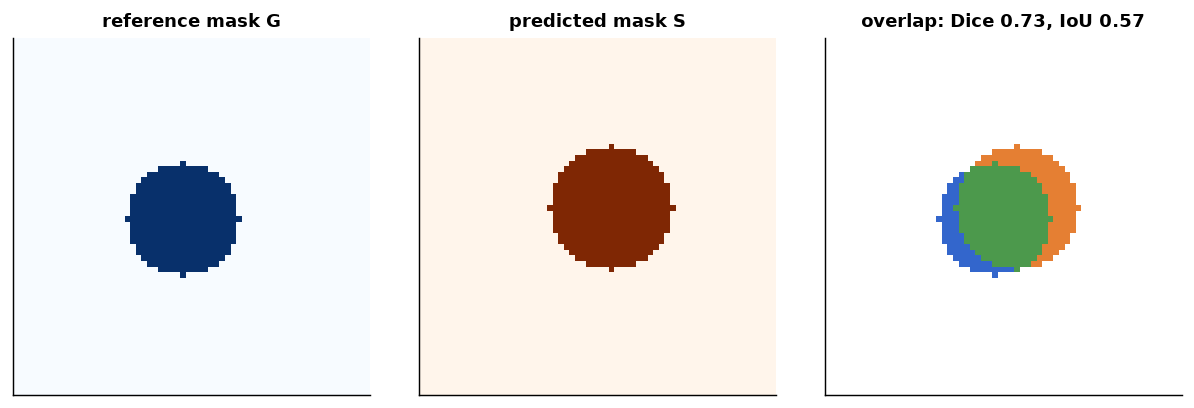

In [12]:
# Dice e IoU sobre un par de máscaras sintéticas: una 'lesión' circular (verdad) y una predicción desplazada y agrandada.
yy, xx = np.mgrid[0:64, 0:64]
truth = (xx - 30) ** 2 + (yy - 32) ** 2 <= 10 ** 2                   # máscara de referencia: radio 10 centrada en (30, 32)
pred  = (xx - 34) ** 2 + (yy - 30) ** 2 <= 11 ** 2                   # máscara predicha: desplazada en (4, -2), radio 11
inter, union = (truth & pred).sum(), (truth | pred).sum()
dice = 2 * inter / (truth.sum() + pred.sum()); iou = inter / union
print(f"|G| = {truth.sum()} px, |S| = {pred.sum()} px, |S & G| = {inter} px, |S | G| = {union} px")
print(f"Dice = {dice:.3f}, IoU = {iou:.3f}, 2*IoU/(1+IoU) = {2 * iou / (1 + iou):.3f}  |  pixel accuracy = {(truth == pred).mean():.3f}")

fig, axes = plt.subplots(1, 3, figsize=(9.5, 3.1))
axes[0].imshow(truth, cmap="Blues"); axes[0].set_title("reference mask G")
axes[1].imshow(pred, cmap="Oranges"); axes[1].set_title("predicted mask S")
overlay = np.zeros((64, 64, 3)); overlay[truth & pred] = (0.3, 0.6, 0.3); overlay[truth & ~pred] = (0.2, 0.4, 0.8); overlay[~truth & pred] = (0.9, 0.5, 0.2)
overlay[~truth & ~pred] = 1
axes[2].imshow(overlay); axes[2].set_title(f"overlap: Dice {dice:.2f}, IoU {iou:.2f}")
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()

<p class="caption"><b>Figura 5.</b> Una máscara de referencia, una predicción desplazada en cuatro píxeles y algo más grande de lo debido, y su solapamiento (verde en ambas, azul omitido, naranja sobresegmentado). La exactitud por píxel supera 0.95 porque la mayor parte de la imagen es fondo, y sin embargo Dice es alrededor de 0.73 e IoU alrededor de 0.57. El Dice entre expertos es de alrededor de 0.9 para órganos bien definidos y de 0.7 o menos para lesiones difusas, lo que acota lo que se puede demostrar que cualquier modelo logra.</p>

### 3.5 Un pipeline de imágenes pequeño y completo, como recordatorio

La celda ejecuta todo el pipeline de la Figura 1 sobre las imágenes de dígitos de 8 × 8 de la Unidad 8 —división estratificada, estandarización, PCA (Unidad 5), una máquina de vectores de soporte (Unidad 3) y un perceptrón multicapa (Unidad 6), ajustados mediante validación cruzada solo sobre el conjunto de entrenamiento— como ensayo para la Sección 4.4.

In [13]:
# Dígitos: PCA + SVM frente a un MLP sobre píxeles crudos, ajustados por validación cruzada de 5 pliegues en el conjunto de entrenamiento, evaluados una vez.
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
digits = datasets.load_digits()
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(digits.data, digits.target, test_size=0.3, random_state=0, stratify=digits.target)
cv5 = StratifiedKFold(5, shuffle=True, random_state=0)
img_models = {
    "PCA(30) + SVM, RBF": GridSearchCV(make_pipeline(StandardScaler(), PCA(30, random_state=0), SVC()),
                                       {"svc__C": [1, 10], "svc__gamma": [0.01, 0.03]}, cv=cv5),
    "MLP (64 hidden units)": GridSearchCV(make_pipeline(StandardScaler(), MLPClassifier((64,), max_iter=600, random_state=0)),
                                          {"mlpclassifier__alpha": [1e-3, 1e-1]}, cv=cv5)}
rows = []
for name, gs in img_models.items():
    t0 = time.perf_counter(); gs.fit(Xd_tr, yd_tr)
    rows.append({"model": name, "CV accuracy (train)": gs.best_score_, "test accuracy": gs.score(Xd_te, yd_te),
                 "best parameters": str(gs.best_params_), "fit time (s)": time.perf_counter() - t0})
img_results = pd.DataFrame(rows).set_index("model").round(3)
img_results

,CV accuracy (train),test accuracy,best parameters,fit time (s)
model,,,,
"PCA(30) + SVM, RBF",0.978,0.976,"{'svc__C': 1, 'svc__gamma': 0.03}",0.732
MLP (64 hidden units),0.976,0.976,{'mlpclassifier__alpha': 0.1},7.162


Ambos pipelines alcanzan alrededor de 0.98 en los dígitos reservados, la estimación por validación cruzada coincide con el puntaje de prueba con una diferencia de menos de un punto porcentual, y el experimento toma segundos. El método importa más que el resultado: el conjunto de prueba se usó una vez, los hiperparámetros se eligieron dentro del conjunto de entrenamiento y ambos modelos se compararon sobre la misma división. La celda siguiente muestra contra qué <em>no</em> protege la tabla.

                       same scanner  different scanner
model                                                 
PCA(30) + SVM, RBF            0.976              0.100
MLP (64 hidden units)         0.976              0.191


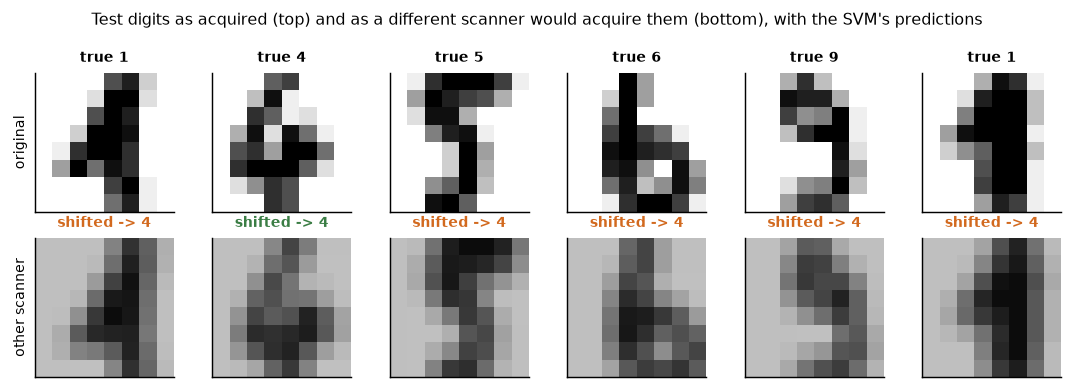

In [14]:
# Cambio de dominio: los mismos modelos aplicados a imágenes de prueba adquiridas por un 'escáner distinto' (más brillante, menor contraste, desenfocado).
from scipy.ndimage import uniform_filter
def other_scanner(X, gain=0.7, offset=4.0, blur=True):
    '''Simulate a scanner with lower contrast (gain), a brightness offset and mild blur, clipped to the 0-16 range.'''
    imgs = X.reshape(-1, 8, 8) * gain + offset
    if blur: imgs = np.stack([uniform_filter(im, size=2, mode="nearest") for im in imgs])
    return np.clip(imgs, 0, 16).reshape(len(X), -1)
Xd_shift = other_scanner(Xd_te)
shift_rows = [{"model": name, "same scanner": gs.score(Xd_te, yd_te), "different scanner": gs.score(Xd_shift, yd_te)}
              for name, gs in img_models.items()]
shift_table = pd.DataFrame(shift_rows).set_index("model").round(3)
print(shift_table.to_string())

fig, axes = plt.subplots(2, 6, figsize=(8.5, 3.0))
for j in range(6):
    axes[0, j].imshow(Xd_te[j].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16); axes[0, j].set_title(f"true {yd_te[j]}", fontsize=8)
    pred = img_models["PCA(30) + SVM, RBF"].predict(Xd_shift[j:j + 1])[0]
    axes[1, j].imshow(Xd_shift[j].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16); axes[1, j].set_title(f"shifted -> {pred}", fontsize=8, color=GREEN if pred == yd_te[j] else ORANGE)
for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel("original", fontsize=8); axes[1, 0].set_ylabel("other scanner", fontsize=8)
fig.suptitle("Test digits as acquired (top) and as a different scanner would acquire them (bottom), with the SVM's predictions", fontsize=9)
fig.tight_layout()

<p class="caption"><b>Figura 6.</b> Seis dígitos de prueba tal como se adquirieron (arriba) y tras un cambio simulado de escáner —menor contraste, un desplazamiento de brillo, un leve desenfoque (abajo)—, con la predicción de PCA + SVM para cada uno (verde correcta, naranja incorrecta). Las imágenes siguen siendo legibles para una persona, y sin embargo la exactitud cae de alrededor de 0.98 a 0.10 para la SVM —nivel de azar; cada dígito desplazado que se muestra se lee como un 4— y a alrededor de 0.19 para el MLP.</p>

El mecanismo es típico: los píxeles del borde de los dígitos de entrenamiento casi siempre valen cero, de modo que el estandarizador aprendió para ellos una media y una varianza cercanas a cero; el desplazamiento de brillo los convierte en valores estandarizados grandes que ninguna imagen de entrenamiento tuvo jamás, y ambos modelos extrapolan. El cambio que más daña no es el más visible para una persona (el desenfoque), sino el que aleja más los datos de la distribución de entrenamiento en la representación del modelo. La evaluación interna honesta fue honesta respecto de la población equivocada, y los dos modelos se vieron afectados de manera distinta, así que la robustez se mide, no se supone. Remedios: validación externa en el sitio de despliegue, adquisición armonizada, aumento de datos con las variaciones esperadas (Unidad 8), monitoreo después del despliegue (Sección 5.6).

<div class="exercise"><h4>Ejercicio 3</h4><p>Varía el cambio: <code>blur=False</code>; luego <code>gain=1.0</code> solo con el desplazamiento de brillo; luego solo el desenfoque. ¿Qué componente daña más a cada modelo? Luego vuelve a ajustar ambos pipelines con imágenes de entrenamiento aumentadas con sus propias copias desplazadas (<code>np.vstack([Xd_tr, other_scanner(Xd_tr)])</code>) y vuelve a evaluar en ambos conjuntos de prueba. ¿Restaura el aumento de datos la exactitud con el cambio, y cuánto cuesta en el conjunto original?</p></div>

## 4. Sistemas de diagnóstico médico (9.3)

### 4.1 Una breve historia

La Unidad 1 describió <strong>MYCIN</strong> (Stanford, 1972–1976), el consultor de antibióticos basado en reglas. Su contemporáneo <strong>INTERNIST-1</strong> (Pittsburgh, desde 1974) abarcaba unas 500 enfermedades y 3,550 manifestaciones, vinculadas mediante una <em>fuerza evocadora</em> (evoking strength) y una <em>frecuencia</em>. En su evaluación de 1982 sobre 19 casos de conferencias clinicopatológicas tuvo un desempeño comparable al de los clínicos del hospital e inferior al de los expertos que discutían los casos, y sus autores dijeron con claridad que no estaba listo para el uso clínico: no podía razonar sobre el tiempo, la anatomía ni la causalidad, y no podía explicarse a sí mismo.<sup class="c"><a href="#r12">[12]</a></sup> Su base de conocimiento se convirtió en <strong>QMR</strong>; <strong>DXplain</strong> todavía genera diagnósticos diferenciales en hospitales universitarios; y <strong>HELP</strong> (LDS Hospital, Salt Lake City) fue el primer sistema de información hospitalaria con lógica de decisión incorporada —alertas disparadas a partir de los datos de laboratorio y farmacia a medida que llegaban—, lo que mostró que el sistema diagnóstico útil es un monitor que habla cuando es necesario, no un consultor al que hay que preguntarle. Estos sistemas no se difundieron por las razones que la Unidad 1 dio para MYCIN —conocimiento frágil adquirido a mano, ningún lugar en el flujo de trabajo, ningún responsable—, y lo que sobrevivió fue la arquitectura de HELP y los propios registros.

### 4.2 Los sistemas de apoyo a la decisión clínica hoy

Un <strong>sistema de apoyo a la decisión clínica</strong> (clinical decision support system, CDSS) presenta información específica del paciente a un clínico en el punto de atención: **alertas y recordatorios** (verificación de interacciones y dosis —basados en reglas, plagados de <em>fatiga de alertas</em>, con tasas de anulación superiores al 90 %—); **puntajes de riesgo y modelos de predicción**; **priorización (triage)** de listas de trabajo según la urgencia predicha; **IA diagnóstica en imágenes** como segundo lector, como tamizaje previo o, en un caso autorizado (Sección 6), como decisión autónoma; y **conjuntos de órdenes y apoyo a la documentación**, que desde 2023 incluyen modelos de lenguaje que redactan notas.

La guía para implementadores de Osheroff y colaboradores destiló los <strong>cinco correctos de los CDSS</strong> (five rights): la <em>información</em> correcta, a la <em>persona</em> correcta (quien puede actuar —no necesariamente el médico—), en el <em>formato</em> correcto, por el <em>canal</em> correcto, en el <em>momento correcto del flujo de trabajo</em> —la lista de verificación para la fase de despliegue que la mayoría de los proyectos se salta—. La etiqueta de <em>datos del modelo</em> (model facts) de Sendak y colaboradores —una página que indica qué predice un modelo, en quiénes se validó, cómo debe y cómo no debe usarse, a quién llamar— es el instrumento para la información correcta en el formato correcto.<sup class="c"><a href="#r31">[31]</a></sup> Rajkomar, Dean y Kohane plantean el punto complementario: los problemas difíciles junto a la cama del paciente son el flujo de datos, la integración en el flujo de trabajo y la evaluación del efecto sobre la atención, no el algoritmo de aprendizaje.<sup class="c"><a href="#r30">[30]</a></sup>

### 4.3 Razonamiento diagnóstico bayesiano y el nomograma de Fagan

Todo sistema diagnóstico actualiza una creencia con evidencia (Unidad 3). La práctica clínica usa la forma del teorema de Bayes en términos de <em>odds</em> (chances), en la que el resultado de una prueba actúa por multiplicación: con odds pre-test $O_0 = p_0/(1-p_0)$ y las <strong>razones de verosimilitud</strong> (likelihood ratios) de la prueba,

<div class="eq">$$\text{LR}^{+} = \frac{\text{sensitivity}}{1 - \text{specificity}}, \qquad \text{LR}^{-} = \frac{1 - \text{sensitivity}}{\text{specificity}}, \qquad O_{\text{post}} = O_0 \times \text{LR}, \qquad p_{\text{post}} = \frac{O_{\text{post}}}{1 + O_{\text{post}}}$$
<span class="where">Sensibilidad = especificidad = 0.90 da $\text{LR}^{+} = 9$ y $\text{LR}^{-} = 0.11$. En escala logarítmica la actualización es aditiva, $\log O_{\text{post}} = \log O_0 + \log \text{LR}$, razón por la cual el nomograma de Fagan es una línea recta.</span></div>

El nomograma de Fagan de 1975 pone las tres cantidades en ejes logarítmicos paralelos, de modo que una línea recta desde la probabilidad pre-test a través de la razón de verosimilitud da la probabilidad post-test.<sup class="c"><a href="#r13">[13]</a></sup> Hace visible el hecho central del diagnóstico —<em>el mismo resultado positivo significa cosas distintas a distintas probabilidades pre-test</em>—, aquí para $\text{LR}^{+} = 9$ en un contexto de tamizaje ($p_0 = 0.05$) y en uno de derivación ($p_0 = 0.37$, la prevalencia en los datos de Wisconsin).

test: sensitivity 0.9, specificity 0.9 -> LR+ = 9.00, LR- = 0.111
 pre-test p   result    LR  post-test p
       0.05 positive 9.000        0.321
       0.37 positive 9.000        0.841
       0.05 negative 0.111        0.006
       0.37 negative 0.111        0.061


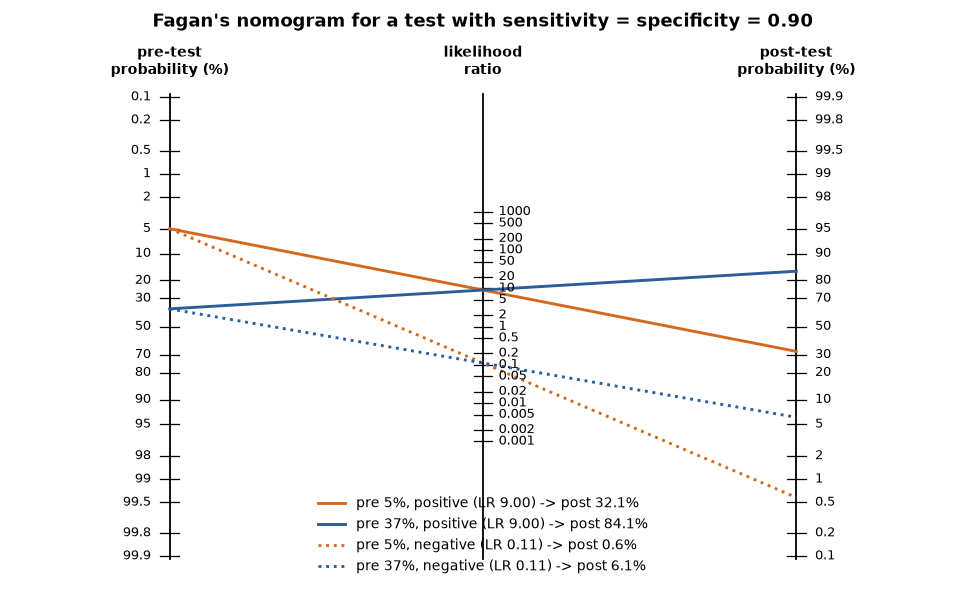

In [15]:
# Nomograma de Fagan: probabilidad pre-test, razón de verosimilitud y probabilidad post-test en ejes paralelos de log-odds.
def post_test(p0, lr):
    odds = p0 / (1 - p0) * lr
    return odds / (1 + odds)
logit = lambda p: np.log(p / (1 - p))
sens, spec = 0.90, 0.90
lr_pos, lr_neg = sens / (1 - spec), (1 - sens) / spec
cases = pd.DataFrame({"pre-test p": [0.05, 0.37, 0.05, 0.37], "result": ["positive", "positive", "negative", "negative"],
                      "LR": [lr_pos, lr_pos, lr_neg, lr_neg]})
cases["post-test p"] = [post_test(p, lr) for p, lr in zip(cases["pre-test p"], cases["LR"])]
print(f"test: sensitivity {sens}, specificity {spec} -> LR+ = {lr_pos:.2f}, LR- = {lr_neg:.3f}")
print(cases.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 4.6))
p_ticks = [0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9, 0.95, 0.98, 0.99, 0.995, 0.998, 0.999]
lr_ticks = [0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]
for p in p_ticks:                                                     # eje izquierdo: pre-test (invertido), eje derecho: post-test
    ax.plot([-0.03, 0.03], [-logit(p)] * 2, "k", lw=0.7); ax.text(-0.06, -logit(p), f"{p * 100:g}", ha="right", va="center", fontsize=7)
    ax.plot([1.97, 2.03], [logit(p)] * 2, "k", lw=0.7); ax.text(2.06, logit(p), f"{p * 100:g}", ha="left", va="center", fontsize=7)
for lr in lr_ticks:                                                   # eje central: razón de verosimilitud, a media escala
    ax.plot([0.97, 1.03], [np.log(lr) / 2] * 2, "k", lw=0.7); ax.text(1.05, np.log(lr) / 2, f"{lr:g}", ha="left", va="center", fontsize=7)
for x in (0, 1, 2): ax.plot([x, x], [-7, 7], "k", lw=1)
for (p0, res, lr, pp), col in zip(cases.itertuples(index=False), [ORANGE, BLUE, ORANGE, BLUE]):
    ax.plot([0, 2], [-logit(p0), logit(pp)], color=col, lw=1.6, ls="-" if res == "positive" else ":",
            label=f"pre {p0:.0%}, {res} (LR {lr:.2f}) -> post {pp:.1%}")
ax.set_xlim(-0.5, 2.5); ax.set_ylim(-7.5, 7.5); ax.axis("off")
for x, t in [(0, "pre-test\nprobability (%)"), (1, "likelihood\nratio"), (2, "post-test\nprobability (%)")]: ax.text(x, 7.6, t, ha="center", fontsize=8, fontweight="bold")
ax.legend(frameon=False, fontsize=7.5, loc="lower center", bbox_to_anchor=(0.5, -0.02)); ax.set_title("Fagan's nomogram for a test with sensitivity = specificity = 0.90", y=1.08)
fig.tight_layout()

<p class="caption"><b>Figura 7.</b> El nomograma de Fagan calculado en código, en escalas de log-odds para que el teorema de Bayes sea una línea recta. El mismo resultado positivo (continuo, LR⁺ = 9) lleva a un paciente de tamizaje del 5 % a alrededor del 32 % y a un paciente derivado del 37 % a alrededor del 84 %; el mismo resultado negativo (punteado, LR⁻ = 0.11) los lleva a alrededor del 0.6 % y del 6 %. Una prueba "90 % exacta" deja a dos de cada tres pacientes de tamizaje con resultado positivo libres de enfermedad.</p>

<div class="box key"><h4>Qué significa esto para un sistema que aprende</h4><p>La salida de un clasificador es una probabilidad post-test <em>a la prevalencia de su conjunto de entrenamiento</em>. Desplegado donde la prevalencia es distinta, sus probabilidades están equivocadas exactamente en la razón de las odds a priori, aunque sus razones de verosimilitud no cambien. Por eso la Sección 4.4 informa la prevalencia de su conjunto de evaluación, la calibración debe volver a verificarse en cada sitio y un valor predictivo positivo citado sin una prevalencia carece de sentido.</p></div>

### 4.4 El proyecto integrador: un modelo diagnóstico completo y honesto

El resto de esta sección construye un modelo diagnóstico para los datos de cáncer de mama de Wisconsin (artículo del conjunto de datos citado en la Unidad 1) como debe construirse un modelo destinado a pacientes, siguiendo el Suplemento S1 y los estándares de la Sección 4.6:

1. **Problema y datos.** Clase positiva = maligno. División estratificada 75/25; el conjunto de prueba se toca una sola vez, al final.
2. **Modelos candidatos.** Máquina de vectores de soporte con kernel RBF, bosque aleatorio, perceptrón multicapa (Unidades 3, 4, 6), cada uno en un pipeline con estandarización para que ninguna estadística de escalamiento se filtre entre pliegues.
3. **Validación cruzada anidada**: búsqueda interna de hiperparámetros con 3 pliegues, estimación externa con 5 pliegues; se selecciona la familia con el AUC externo más alto.
4. **Calibración** mediante escalamiento de Platt (Platt scaling), ajustada por validación cruzada dentro del conjunto de entrenamiento.
5. **Evaluación en el conjunto de prueba**: ROC-AUC, curva de confiabilidad y puntaje de Brier, curva de decisión.
6. **Umbral** a partir del costo relativo de un cáncer no detectado y de una biopsia innecesaria, elegido sobre predicciones de entrenamiento obtenidas por validación cruzada.
7. **Verificación por subgrupos** y **ficha del modelo** (model card).

In [16]:
# Proyecto integrador, pasos 1-2: definición del problema, división estratificada y tres familias candidatas como pipelines escalados con grillas de búsqueda.
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate, cross_val_predict
X_tr, X_te, y_tr, y_te = train_test_split(Xc, yc, test_size=0.25, random_state=0, stratify=yc)
inner, outer = StratifiedKFold(3, shuffle=True, random_state=0), StratifiedKFold(5, shuffle=True, random_state=0)
def tuned(estimator, grid):
    return GridSearchCV(make_pipeline(StandardScaler(), estimator), grid, cv=inner, scoring="roc_auc")
families = {
    "SVM, RBF (Unit 3)":      tuned(SVC(random_state=0), {"svc__C": [0.3, 1, 3, 10], "svc__gamma": [0.003, 0.01, 0.03]}),
    "Random forest (Unit 4)": tuned(RandomForestClassifier(n_estimators=150, random_state=0),
                                    {"randomforestclassifier__max_features": [3, 8], "randomforestclassifier__min_samples_leaf": [1, 3]}),
    "MLP (Unit 6)":           tuned(MLPClassifier(max_iter=1500, random_state=0),
                                    {"mlpclassifier__hidden_layer_sizes": [(16,), (32,)], "mlpclassifier__alpha": [1e-2, 1.0]}),
}
print(f"training set: {len(y_tr)} cases ({y_tr.mean():.1%} malignant) | test set: {len(y_te)} cases ({y_te.mean():.1%} malignant), locked away")
print("hyper-parameter combinations searched per family:", {k: int(np.prod([len(v) for v in s.param_grid.values()])) for k, s in families.items()})

training set: 426 cases (37.3% malignant) | test set: 143 cases (37.1% malignant), locked away
hyper-parameter combinations searched per family: {'SVM, RBF (Unit 3)': 12, 'Random forest (Unit 4)': 4, 'MLP (Unit 6)': 4}


In [17]:
# Proyecto integrador, paso 3: validación cruzada anidada (ajuste interno con 3 pliegues, estimación externa con 5 pliegues) de las tres familias.
rows = []
for name, search in families.items():
    t0 = time.perf_counter()
    cvres = cross_validate(search, X_tr, y_tr, cv=outer, scoring=["roc_auc", "accuracy"], return_estimator=True)
    rows.append({"family": name, "outer AUC": cvres["test_roc_auc"].mean(), "AUC sd": cvres["test_roc_auc"].std(),
                 "outer accuracy": cvres["test_accuracy"].mean(),
                 "best parameters (fold 1)": str({k.split("__")[1]: v for k, v in cvres["estimator"][0].best_params_.items()}),
                 "time (s)": time.perf_counter() - t0})
nested = pd.DataFrame(rows).set_index("family")
chosen = nested["outer AUC"].idxmax()
print(f"selected family (highest outer AUC): {chosen}")
nested.round(3)

selected family (highest outer AUC): SVM, RBF (Unit 3)


,outer AUC,AUC sd,outer accuracy,best parameters (fold 1),time (s)
family,,,,,
"SVM, RBF (Unit 3)",0.994,0.008,0.972,"{'C': 3, 'gamma': 0.03}",0.820
Random forest (Unit 4),0.990,0.008,0.951,"{'max_features': 3, 'min_samples_leaf': 1}",5.795
MLP (Unit 6),0.992,0.006,0.981,"{'alpha': 1.0, 'hidden_layer_sizes': (32,)}",5.845


Las tres familias alcanzan un AUC en los pliegues externos superior a 0.99 y difieren en unas pocas milésimas —menos que la desviación estándar entre pliegues—, de modo que la tabla no da fundamentos sólidos para preferir una; el código selecciona la media más alta, en esta ejecución la máquina de vectores de soporte, y la selección es en sí misma una elección hecha con datos de entrenamiento. La Unidad 3, Sección 8.1, hizo la misma comparación sin un conjunto de prueba reservado; solo los números actuales estiman el desempeño en casos nuevos, porque el conjunto de prueba todavía no se ha usado.

In [18]:
# Proyecto integrador, pasos 4-5a: reajustar la familia seleccionada sobre todo el conjunto de entrenamiento, calibrar sus probabilidades, evaluar una vez en el conjunto de prueba.
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss, confusion_matrix, roc_curve
best_search = families[chosen].fit(X_tr, y_tr)
core = best_search.best_estimator_.steps[-1][1]                                 # el estimador ajustado sin el escalador
final_model = make_pipeline(StandardScaler(), CalibratedClassifierCV(core, method="sigmoid", cv=5, ensemble=False)).fit(X_tr, y_tr)
p_te = final_model.predict_proba(X_te)[:, 1]
auc_te, brier_te = roc_auc_score(y_te, p_te), brier_score_loss(y_te, p_te)
tn, fp, fn, tp = confusion_matrix(y_te, p_te >= 0.5).ravel()
print(f"tuned parameters: {best_search.best_params_}")
print(f"test set ({len(y_te)} cases): ROC-AUC {auc_te:.3f} | Brier score {brier_te:.3f} (0 is perfect; {y_te.mean() * (1 - y_te.mean()):.3f} for a constant prediction at prevalence)")
print(f"at threshold 0.5: TP {tp}, FN {fn}, FP {fp}, TN {tn} -> sensitivity {tp / (tp + fn):.3f}, specificity {tn / (tn + fp):.3f}, PPV {tp / (tp + fp):.3f}")

tuned parameters: {'svc__C': 10, 'svc__gamma': 0.01}
test set (143 cases): ROC-AUC 0.997 | Brier score 0.023 (0 is perfect; 0.233 for a constant prediction at prevalence)
at threshold 0.5: TP 51, FN 2, FP 4, TN 86 -> sensitivity 0.962, specificity 0.956, PPV 0.927


Ajustado una vez con 426 casos de entrenamiento y evaluado una vez con 143 casos de prueba, el modelo alcanza un AUC de prueba de alrededor de 0.997 y un puntaje de Brier de alrededor de 0.02 (0.23 si se predice la prevalencia para todos); con umbral 0.5 omite 2 de 53 casos malignos y genera 4 falsas alarmas entre 90 benignos. Estos son los números que informa un artículo. Las celdas siguientes preguntan lo que un artículo habitualmente no pregunta: ¿están calibradas las probabilidades?, ¿es útil el modelo en los umbrales que usan los clínicos?, ¿y es 0.5 el umbral correcto?

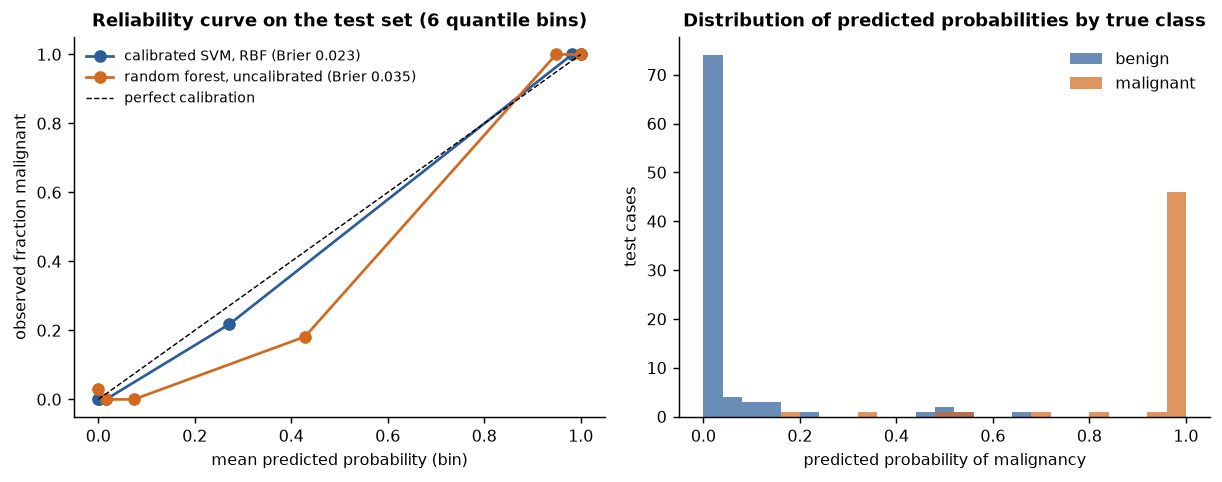

In [19]:
# Proyecto integrador, paso 5b: calibración - ¿coinciden las probabilidades predichas con las frecuencias observadas? Comparado con el bosque aleatorio sin calibrar.
rf_plain = families["Random forest (Unit 4)"].fit(X_tr, y_tr).best_estimator_
p_rf = rf_plain.predict_proba(X_te)[:, 1]
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
for p, name, col in [(p_te, f"calibrated {chosen.split(' (')[0]}", BLUE), (p_rf, "random forest, uncalibrated", ORANGE)]:
    frac_pos, mean_pred = calibration_curve(y_te, p, n_bins=6, strategy="quantile")
    axes[0].plot(mean_pred, frac_pos, "o-", color=col, label=f"{name} (Brier {brier_score_loss(y_te, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8, label="perfect calibration"); axes[0].set_xlabel("mean predicted probability (bin)"); axes[0].set_ylabel("observed fraction malignant")
axes[0].set_title("Reliability curve on the test set (6 quantile bins)"); axes[0].legend(frameon=False, fontsize=7.5)
axes[1].hist(p_te[y_te == 0], bins=25, range=(0, 1), alpha=0.7, color=BLUE, label="benign"); axes[1].hist(p_te[y_te == 1], bins=25, range=(0, 1), alpha=0.7, color=ORANGE, label="malignant")
axes[1].set_xlabel("predicted probability of malignancy"); axes[1].set_ylabel("test cases"); axes[1].set_title("Distribution of predicted probabilities by true class"); axes[1].legend(frameon=False)
fig.tight_layout()

<p class="caption"><b>Figura 8.</b> Izquierda: curvas de confiabilidad en el conjunto de prueba —casos agrupados en intervalos según la probabilidad predicha, predicción media frente a fracción observada de malignos—; un modelo calibrado se ubica sobre la diagonal. Derecha: probabilidades predichas por el modelo calibrado según la clase verdadera; la mayoría de los casos se ubica cerca de 0 o de 1. El puntaje de Brier (leyenda) es la diferencia cuadrática media entre la probabilidad predicha y el desenlace.</p>

La discriminación y la calibración son propiedades distintas: las fracciones de votos de un bosque aleatorio están comprimidas hacia el centro, por lo que su curva de confiabilidad se aleja de la diagonal aunque su AUC sea alto. El escalamiento de Platt ajusta una regresión logística desde el puntaje al desenlace sobre predicciones de entrenamiento obtenidas por validación cruzada y corrige la distorsión. La calibración importa porque el umbral del paso 6 y el beneficio neto del paso 5 viven <em>en la escala de probabilidad</em>.

net benefit (true positives per 100 patients, net of harm from false positives):
           model  biopsy all  biopsy none
threshold                                
0.05        36.5        33.8          0.0
0.10        36.2        30.1          0.0
0.20        35.3        21.3          0.0
0.33        34.6         6.1          0.0
0.50        32.9       -25.9          0.0


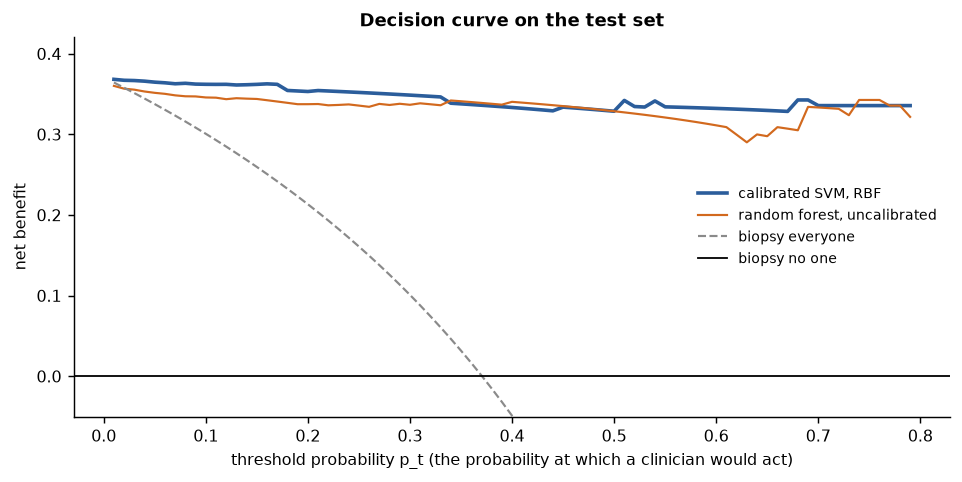

In [20]:
# Proyecto integrador, paso 5c: análisis de curva de decisión (Vickers & Elkin 2006) en numpy - beneficio neto frente a la probabilidad umbral.
def net_benefit(y, p, thresholds):
    '''Net benefit = TP/n - FP/n * t/(1-t): true positives per patient minus false positives weighted by the odds of the threshold.'''
    y = np.asarray(y); out = []
    for t in thresholds:
        pred = p >= t
        out.append((pred & (y == 1)).sum() / len(y) - (pred & (y == 0)).sum() / len(y) * t / (1 - t))
    return np.array(out)
thresholds = np.arange(0.01, 0.80, 0.01)
prev = y_te.mean()
nb_model, nb_rf = net_benefit(y_te, p_te, thresholds), net_benefit(y_te, p_rf, thresholds)
nb_all = prev - (1 - prev) * thresholds / (1 - thresholds)                 # 'biopsiar a todos'
dca = pd.DataFrame({"threshold": [0.05, 0.10, 0.20, 0.33, 0.50], }).set_index("threshold")
dca["model"] = net_benefit(y_te, p_te, dca.index); dca["biopsy all"] = prev - (1 - prev) * dca.index / (1 - dca.index); dca["biopsy none"] = 0.0
print("net benefit (true positives per 100 patients, net of harm from false positives):"); print((dca * 100).round(1).to_string())

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(thresholds, nb_model, color=BLUE, lw=2, label=f"calibrated {chosen.split(' (')[0]}")
ax.plot(thresholds, nb_rf, color=ORANGE, lw=1.2, label="random forest, uncalibrated")
ax.plot(thresholds, nb_all, color=GREY, lw=1.2, ls="--", label="biopsy everyone"); ax.axhline(0, color="k", lw=1, label="biopsy no one")
ax.set_ylim(-0.05, prev + 0.05); ax.set_xlabel("threshold probability p_t (the probability at which a clinician would act)"); ax.set_ylabel("net benefit")
ax.set_title("Decision curve on the test set"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout()

<p class="caption"><b>Figura 9.</b> Curvas de decisión en el conjunto de prueba. El eje horizontal es la <em>probabilidad umbral</em> $p_t$ a la que un clínico o un paciente optaría por la biopsia —cómo se pondera un cáncer no detectado frente a un procedimiento innecesario—; el eje vertical es el beneficio neto. "Biopsy everyone" (biopsiar a todos, línea discontinua) y "biopsy no one" (no biopsiar a nadie, línea cero) acotan la región en la que un modelo es útil; el modelo calibrado se ubica por encima de ambas en todo el rango plausible.</p>

El análisis de curva de decisión de Vickers y Elkin responde lo que el AUC y la calibración no responden: <em>¿decidir con este modelo llevaría a mejores decisiones que no usarlo?</em><sup class="c"><a href="#r14">[14]</a></sup> Su único supuesto es que un clínico que actúa a la probabilidad $p_t$ valora un verdadero positivo como $(1-p_t)/p_t$ falsos positivos —quien biopsia al 10 % acepta nueve biopsias innecesarias por cada cáncer encontrado—, de modo que

<div class="eq">$$\text{NB}(p_t) = \frac{\text{TP}(p_t)}{n} - \frac{\text{FP}(p_t)}{n} \cdot \frac{p_t}{1 - p_t}$$
<span class="where">en verdaderos positivos por paciente. "Biopsiar a todos" da $\text{NB} = \pi - (1-\pi)\,p_t/(1-p_t)$, con $\pi$ la prevalencia; "no biopsiar a nadie" da 0. Un modelo es útil en $p_t$ solo si su curva se ubica por encima de ambas.</span></div>

La tabla sobre la figura lee la curva en cinco umbrales: con $p_t = 0.10$, el modelo produce alrededor de 36 verdaderos positivos por cada 100 pacientes, descontado el daño, frente a alrededor de 30 al biopsiar a todos. Cerca de $p_t \to 0$, toda estrategia converge a "biopsiar a todos": un clínico que va a biopsiar a cualquier probabilidad no necesita un modelo.

### 4.5 Elegir el umbral según el costo clínico

El umbral por defecto de 0.5 trata un cáncer no detectado y una biopsia innecesaria como igualmente costosos. Si una neoplasia maligna no detectada es $c$ veces peor, el costo esperado de un umbral es $c \cdot \text{FN} + \text{FP}$ y el óptimo de la teoría de decisión (Unidad 3, Sección 3.2) es actuar cuando $p > 1/(1+c)$. La celda elige el umbral de manera empírica a partir de <em>predicciones de entrenamiento obtenidas por validación cruzada</em> e informa la matriz de confusión del conjunto de prueba y las razones de verosimilitud en ese umbral.

In [21]:
# Proyecto integrador, paso 6: umbral según costo clínico (FN = c x FP), elegido sobre predicciones de ENTRENAMIENTO por validación cruzada, aplicado una vez al conjunto de prueba.
p_cv = cross_val_predict(final_model, X_tr, y_tr, cv=outer, method="predict_proba")[:, 1]
def expected_cost(y, p, t, c):
    tn_, fp_, fn_, tp_ = confusion_matrix(y, p >= t).ravel(); return c * fn_ + fp_
grid_t = np.arange(0.02, 0.95, 0.01)
rows = []
for c in [1, 3, 5, 10]:
    costs = np.array([expected_cost(y_tr, p_cv, t, c) for t in grid_t]); t_star = grid_t[costs.argmin()]
    tn_, fp_, fn_, tp_ = confusion_matrix(y_te, p_te >= t_star).ravel()
    sens_, spec_ = tp_ / (tp_ + fn_), tn_ / (tn_ + fp_)
    rows.append({"cost ratio c": c, "theoretical 1/(1+c)": 1 / (1 + c), "chosen threshold": t_star, "test FN": fn_, "test FP": fp_,
                 "sensitivity": sens_, "specificity": spec_, "LR+": sens_ / (1 - spec_) if spec_ < 1 else np.inf, "LR-": (1 - sens_) / spec_})
thr_table = pd.DataFrame(rows).set_index("cost ratio c")
T_STAR = thr_table.loc[5, "chosen threshold"]
print(f"operating threshold adopted (c = 5): {T_STAR:.2f}")
thr_table.round(3)

operating threshold adopted (c = 5): 0.34


,theoretical 1/(1+c),chosen threshold,test FN,test FP,sensitivity,specificity,LR+,LR-
cost ratio c,,,,,,,,
1,0.500,0.46,2,4,0.962,0.956,21.651,0.039
3,0.250,0.34,2,5,0.962,0.944,17.321,0.040
5,0.167,0.34,2,5,0.962,0.944,17.321,0.040
10,0.091,0.10,0,11,1.000,0.878,8.182,0.000


A medida que aumenta la razón de costos, el umbral baja, la sensibilidad sube, la especificidad baja y los falsos negativos del conjunto de prueba llegan a cero a cambio de unos pocos falsos positivos más. Los umbrales empíricos siguen a $1/(1+c)$ solo de manera aproximada, porque las probabilidades calibradas se concentran cerca de 0 y de 1 y la superficie de costo es plana en un rango amplio —varios umbrales dan la misma matriz de confusión—. Adoptamos $c = 5$. Las razones de verosimilitud en ese umbral se trasladan directamente a la Figura 7: la probabilidad post-test tras una salida positiva o negativa depende de la prevalencia en el lugar donde se usa el modelo.

La razón de costos no le corresponde elegirla solo al ingeniero: codifica un juicio clínico y ético que pertenece a los clínicos, a los pacientes y a la institución. La obligación del ingeniero es exponer la elección y mostrar sus consecuencias, como lo hacen la tabla y la curva de decisión.

### 4.6 Verificación por subgrupos, ficha del modelo y estándares de reporte

Un modelo bueno en promedio puede ser malo en un subgrupo —un rango de edad, un escáner, un hospital—. Los datos de Wisconsin no contienen variables demográficas, así que la celda simula la verificación más simple: casos de prueba asignados al azar a dos "hospitales", donde el desempeño debería ser igual por construcción. La Sección 5.2 la repite con una variable de subgrupo <em>correlacionada</em> con el desenlace.

In [22]:
# Proyecto integrador, paso 7a: desempeño por subgrupo. Aquí el subgrupo es una etiqueta aleatoria de 'hospital', así que las diferencias son ruido de muestreo.
rng = np.random.default_rng(0)
hospital = rng.choice(["Hospital A", "Hospital B"], size=len(y_te), p=[0.6, 0.4])
def subgroup_report(y, p, group, t):
    rows = []
    for g in np.unique(group):
        m = group == g; tn_, fp_, fn_, tp_ = confusion_matrix(y[m], p[m] >= t).ravel()
        rows.append({"group": g, "n": int(m.sum()), "prevalence": y[m].mean(), "AUC": roc_auc_score(y[m], p[m]),
                     "sensitivity": tp_ / (tp_ + fn_), "specificity": tn_ / (tn_ + fp_), "flagged": (p[m] >= t).mean()})
    return pd.DataFrame(rows).set_index("group")
y_te_arr = y_te.to_numpy()
subgroup_report(y_te_arr, p_te, hospital, T_STAR).round(3)

,n,prevalence,AUC,sensitivity,specificity,flagged
group,,,,,,
Hospital A,78,0.333,0.997,0.962,0.923,0.372
Hospital B,65,0.415,0.998,0.963,0.974,0.415


Los dos hospitales tienen la misma sensibilidad y difieren en alrededor de cinco centésimas en especificidad, con menos de cien casos cada uno. Primera lección: con $n \approx 60$–90 por grupo, un falso negativo adicional mueve la sensibilidad en dos a cuatro puntos, de modo que tales diferencias son compatibles con un desempeño igual, y deben informarse intervalos de confianza, no estimaciones puntuales. Segunda (Sección 2.6): de diez subgrupos examinados, el peor se verá mal por azar, y un hallazgo en un subgrupo debe confirmarse con datos nuevos antes de actuar en consecuencia.

La <strong>ficha del modelo</strong> (model card) de Mitchell y colaboradores es un documento estructurado que indica, en campos fijos, qué es un modelo y para qué sirve, con qué datos se entrenó y evaluó, cómo se desempeña en general y por subgrupo, y cuáles son sus limitaciones y consideraciones éticas.<sup class="c"><a href="#r15">[15]</a></sup> La celda arma una a partir de las cantidades calculadas más arriba, de modo que cada número sea rastreable hasta una celda de este notebook.

In [23]:
# Proyecto integrador, paso 7b: una ficha del modelo armada a partir de las cantidades calculadas (Mitchell et al. 2019).
thr_row = thr_table.loc[5]
card = pd.DataFrame({"field": [
    "Model details", "Intended use", "Out-of-scope use", "Training data", "Evaluation data", "Discrimination", "Calibration",
    "Operating point", "Performance at operating point", "Clinical utility", "Subgroup performance", "Ethical considerations", "Caveats and limitations"],
  "content": [
    f"{chosen}; pipeline StandardScaler -> tuned estimator {best_search.best_params_} -> Platt (sigmoid) calibration, 5-fold inside training set. scikit-learn {sklearn.__version__}.",
    "Probability that a fine-needle aspirate of a breast mass is malignant, from 30 nuclear-morphology features, to support (not replace) the decision to biopsy in a referral setting.",
    "Screening populations (prevalence far below 37 %), images from other laboratories or feature-extraction software, any use without a pathologist in the loop.",
    f"{len(y_tr)} aspirates (Wisconsin Diagnostic Breast Cancer, 1989-1991, one institution), {y_tr.mean():.1%} malignant.",
    f"{len(y_te)} held-out aspirates from the same source (internal validation only), {y_te.mean():.1%} malignant. No external validation has been performed.",
    f"ROC-AUC {auc_te:.3f} on the test set; nested-CV AUC on the training set {nested.loc[chosen, 'outer AUC']:.3f} +/- {nested.loc[chosen, 'AUC sd']:.3f}.",
    f"Brier score {brier_te:.3f}; reliability curve close to the diagonal (Figure 8).",
    f"Threshold {T_STAR:.2f}, chosen on cross-validated training predictions for a cost ratio of 5 (missed cancer : unnecessary biopsy).",
    f"Sensitivity {thr_row['sensitivity']:.3f}, specificity {thr_row['specificity']:.3f}, LR+ {thr_row['LR+']:.1f}, LR- {thr_row['LR-']:.3f}; {int(thr_row['test FN'])} false negatives and {int(thr_row['test FP'])} false positives among {len(y_te)} test cases.",
    "Net benefit above 'biopsy all' and 'biopsy none' for threshold probabilities between 0.05 and 0.50 (Figure 9).",
    "Equal within sampling error across two randomly assigned hospitals (Section 4.6); no demographic variables available, so fairness by age, ethnicity or socioeconomic group is UNTESTED.",
    "Label is the biopsy result; features depend on one laboratory's imaging and segmentation. Any deployment requires local validation, monitoring, and informed patients.",
    "Single-site, three-decade-old data; small test set (confidence intervals wide); probabilities valid only at the training prevalence; the model has not been evaluated prospectively or in a trial."]})
with pd.option_context("display.max_colwidth", 200):
    display(card.set_index("field"))

,content
field,
Model details,"SVM, RBF (Unit 3); pipeline StandardScaler -> tuned estimator {'svc__C': 10, 'svc__gamma': 0.01} -> Platt (sigmoid) calibration, 5-fold inside training set. scikit-learn 1.9.0."
Intended use,"Probability that a fine-needle aspirate of a breast mass is malignant, from 30 nuclear-morphology features, to support (not replace) the decision to biopsy in a referral setting."
Out-of-scope use,"Screening populations (prevalence far below 37 %), images from other laboratories or feature-extraction software, any use without a pathologist in the loop."
Training data,"426 aspirates (Wisconsin Diagnostic Breast Cancer, 1989-1991, one institution), 37.3% malignant."
Evaluation data,"143 held-out aspirates from the same source (internal validation only), 37.1% malignant. No external validation has been performed."
Discrimination,ROC-AUC 0.997 on the test set; nested-CV AUC on the training set 0.994 +/- 0.008.
Calibration,Brier score 0.023; reliability curve close to the diagonal (Figure 8).
Operating point,"Threshold 0.34, chosen on cross-validated training predictions for a cost ratio of 5 (missed cancer : unnecessary biopsy)."
Performance at operating point,"Sensitivity 0.962, specificity 0.944, LR+ 17.3, LR- 0.040; 2 false negatives and 5 false positives among 143 test cases."


Cada fila de la ficha es un número calculado más arriba o una declaración de lo que <em>no</em> se hizo —solo validación interna, equidad no evaluada, prevalencia de uso restringida, sin evaluación prospectiva—, y el segundo tipo importa más: el lector sabe qué evidencia falta antes de decidir si usar el modelo.

**Estándares de reporte.** <strong>TRIPOD+AI</strong> (2024) rige el reporte del desarrollo y la validación de un modelo de predicción —datos, desenlace, tamaño muestral, construcción del modelo, cada medida de desempeño con su incertidumbre, equidad, disponibilidad del código y de los datos—: la ficha del modelo convertida en lista de verificación para un manuscrito.<sup class="c"><a href="#r16">[16]</a></sup> <strong>DECIDE-AI</strong> (2022) rige la <em>evaluación clínica temprana</em> de un sistema de apoyo a la decisión y pide lo que un artículo de desarrollo no puede contener: cómo interactuaron los usuarios con él, con qué frecuencia lo anularon, qué errores surgieron, cómo se monitoreó la seguridad.<sup class="c"><a href="#r18">[18]</a></sup> <strong>CONSORT-AI</strong> y <strong>SPIRIT-AI</strong> (2020) extienden los estándares para ensayos aleatorizados y protocolos a las intervenciones con un componente de IA.<sup class="c"><a href="#r17">[17]</a></sup> Los tres responden las tres preguntas de la Sección 3.3: ¿predice el modelo?, ¿pueden usarlo los clínicos?, ¿mejora la atención el usarlo?

### 4.7 Por qué la mayoría de los modelos de predicción nunca llega a la práctica

Cada año se publican miles de modelos de predicción clínica y muy pocos se usan. El COVID-19 dio la demostración más clara: la revisión sistemática viva de Wynants y colaboradores evaluó cada modelo diagnóstico o pronóstico publicado —232 a mediados de 2020, varios cientos desde entonces— con la herramienta de riesgo de sesgo PROBAST. Casi todos tenían un riesgo de sesgo alto o poco claro, por razones que forman un catálogo de las advertencias de este curso —controles no representativos, exclusión de pacientes que aún no habían presentado el desenlace, sobreajuste por pocos eventos, reporte demasiado vago para permitir la validación, desempeño estimado con los datos de desarrollo—, y ninguno fue recomendado para uso clínico.<sup class="c"><a href="#r19">[19]</a></sup> La falla no estuvo en los algoritmos —en su mayoría regresiones logísticas y ensambles de árboles—, sino en el <em>proceso</em>: evaluación, fuga de datos, validación externa. La revisión de Topol llegó a la misma conclusión desde la dirección opuesta: de los muchos sistemas que igualan a los especialistas de manera retrospectiva, un puñado ha sido evaluado prospectivamente y menos aún en ensayos que midan desenlaces de los pacientes.<sup class="c"><a href="#r28">[28]</a></sup> El modelo del proyecto integrador, de un solo sitio y con validación interna, es un modelo en etapa de desarrollo, y su ficha lo dice.

<div class="exercise"><h4>Ejercicio 4</h4><p>Fuerza el MLP como la familia seleccionada (<code>chosen = "MLP (Unit 6)"</code> antes del paso 4) y compara la curva de calibración, la curva de decisión y el umbral de operación con los de la SVM. Luego introduce una fuga deliberada —ajusta <code>StandardScaler</code> sobre los 569 casos antes de la división— y observa si cambia algún número de la ficha del modelo. ¿Por qué esta fuga en particular es pequeña aquí, y cuándo sería grande?</p></div>

## 5. Ética profesional en el trabajo con datos (9.4)

La Unidad 1, Sección 7, introdujo la ética de los datos de salud a través de la reidentificación, el cambio en la distribución de los datos (dataset shift), el sesgo en las etiquetas y el marco regulatorio. Esta sección se construye sobre ella en seis partes: el ciclo de vida de los datos; la equidad definida con la precisión suficiente para poder medirla; la explicabilidad y sus límites; la privacidad más allá de la desidentificación; la gobernanza y la ley; la lista de verificación final. El registro es el de Char, Shah y Magnus: las preguntas éticas no están separadas de las de ingeniería, porque las elecciones de etiqueta, datos, umbral y despliegue <em>son</em> las elecciones éticas.<sup class="c"><a href="#r32">[32]</a></sup>

### 5.1 El ciclo de vida de los datos y los deberes del ingeniero

Los datos sobre pacientes pasan por una secuencia de estados, y el ingeniero que construye un sistema que aprende es responsable en cada uno de ellos.

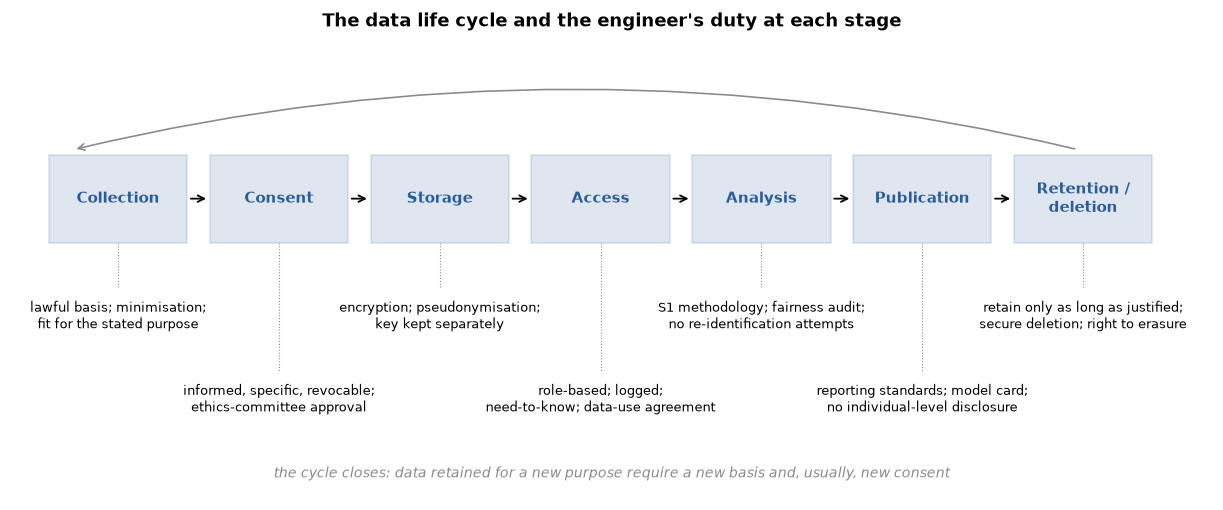

In [24]:
# El ciclo de vida de los datos con el deber del ingeniero en cada etapa (esquemático).
stages = [("Collection", "lawful basis; minimisation;\nfit for the stated purpose"),
          ("Consent", "informed, specific, revocable;\nethics-committee approval"),
          ("Storage", "encryption; pseudonymisation;\nkey kept separately"),
          ("Access", "role-based; logged;\nneed-to-know; data-use agreement"),
          ("Analysis", "S1 methodology; fairness audit;\nno re-identification attempts"),
          ("Publication", "reporting standards; model card;\nno individual-level disclosure"),
          ("Retention /\ndeletion", "retain only as long as justified;\nsecure deletion; right to erasure")]
fig, ax = plt.subplots(figsize=(9.5, 4.0))
ax.set_xlim(0, 10); ax.set_ylim(0, 4.7); ax.axis("off")
w = 9.4 / len(stages)
for i, (name, duty) in enumerate(stages):
    x = 0.3 + i * w
    ax.add_patch(plt.Rectangle((x, 2.6), w * 0.86, 0.9, facecolor=BLUE, alpha=0.15, edgecolor=BLUE))
    ax.text(x + w * 0.43, 3.05, name, ha="center", va="center", fontsize=8.5, fontweight="bold", color=BLUE)
    y_duty = 1.85 if i % 2 == 0 else 1.0                                   # deberes escalonados en dos filas para evitar solapamiento
    ax.plot([x + w * 0.43] * 2, [2.6, y_duty + 0.28], color=GREY, lw=0.6, ls=":")
    ax.text(x + w * 0.43, y_duty, duty, ha="center", va="center", fontsize=7)
    if i < len(stages) - 1: ax.annotate("", xy=(x + w, 3.05), xytext=(x + w * 0.86, 3.05), arrowprops=dict(arrowstyle="->", lw=1))
ax.annotate("", xy=(0.5, 3.55), xytext=(0.3 + 6 * w + w * 0.4, 3.55), arrowprops=dict(arrowstyle="->", lw=0.9, color=GREY, connectionstyle="arc3,rad=0.12"))
ax.text(5, 0.2, "the cycle closes: data retained for a new purpose require a new basis and, usually, new consent", ha="center", fontsize=7.5, color=GREY, style="italic")
ax.set_title("The data life cycle and the engineer's duty at each stage")
fig.tight_layout()

<p class="caption"><b>Figura 10.</b> Siete etapas de la vida de un conjunto de datos de salud con el deber del ingeniero en cada una —habitualmente la misma persona que solicitó la extracción, guarda la clave de los seudónimos y decide qué se publica—.</p>

**Recolección y propósito.** Solo para un propósito declarado y solo en la medida necesaria (<em>minimización</em>); el GDPR y la Ley 21.719 de Chile hacen ilícito "recolectar todo" sin una base legal, y los datos recolectados para la atención no quedan por ello disponibles para la investigación. **Consentimiento y revisión ética.** Consentimiento informado, específico y revocable, o una dispensa justificada, más la aprobación de un comité de ética de la investigación (en Chile, el <em>Comité Ético Científico</em>, Ley 20.120). **Almacenamiento y acceso.** Seudonimización con la clave guardada por separado, cifrado, acceso basado en roles y registrado, un acuerdo de uso de datos —el ingeniero que copia una extracción a un computador portátil ha incumplido los cuatro—. **Análisis.** La metodología de S1 es un requisito ético —un modelo sobrestimado por fuga de datos daña a los pacientes en los que falla—, con una auditoría de equidad y sin intentos de reidentificación no autorizados. **Publicación.** Los estándares de la Sección 4.6; ningún individuo expuesto; código y, cuando sea lícito, datos compartidos. **Retención y eliminación.** Solo mientras lo requiera el propósito, con eliminación segura y respetando el derecho de supresión —y un modelo entrenado puede retener por sí mismo información sobre individuos (Sección 5.4)—.

### 5.2 Equidad: definiciones, el resultado de imposibilidad y una auditoría

"Equitativo" (fair) tiene varios significados precisos para un clasificador, y entran en conflicto. Con el desenlace $Y$, la decisión $\hat Y$, la probabilidad predicha $\hat p$ y un atributo sensible $A$ con grupos $a, b$:

<div class="eq">$$\begin{aligned}
\text{Demographic parity:}\quad & P(\hat Y = 1 \mid A = a) = P(\hat Y = 1 \mid A = b) \\
\text{Equalised odds:}\quad & P(\hat Y = 1 \mid Y = y, A = a) = P(\hat Y = 1 \mid Y = y, A = b) \quad \text{for } y \in \{0, 1\} \\
\text{Calibration within groups:}\quad & P(Y = 1 \mid \hat p = p, A = a) = P(Y = 1 \mid \hat p = p, A = b) = p \quad \text{for all } p
\end{aligned}$$
<span class="where">La misma fracción de cada grupo marcada / igual sensibilidad e igual tasa de falsos positivos / un 0.3 predicho significa 30 % en todos los grupos.</span></div>

La paridad demográfica (demographic parity) es apropiada cuando las tasas base <em>deberían</em> ser iguales y cualquier diferencia es sesgo en las etiquetas —el caso de Obermeyer de la Unidad 1—.<sup class="c"><a href="#r29">[29]</a></sup> Es inapropiada cuando las tasas base difieren genuinamente: la incidencia del cáncer de mama aumenta con la edad, y marcar fracciones iguales de personas de 30 y de 65 años dejaría sin detectar cánceres en las mayores o sobretrataría a las jóvenes. Las probabilidades igualadas (equalised odds) y la calibración son entonces los criterios —y Chouldechova (analizando el puntaje de reincidencia COMPAS) y Kleinberg, Mullainathan y Raghavan (en un teorema general) demostraron que <strong>cuando las tasas base difieren entre grupos y el clasificador es imperfecto, la calibración dentro de los grupos y la igualdad de las tasas de falsos positivos y de falsos negativos no pueden cumplirse todas a la vez</strong>—.<sup class="c"><a href="#r20">[20]</a>,<a href="#r21">[21]</a></sup> Hay que <em>elegir</em> qué equidad satisfacer, y la elección es un juicio de valor sobre los daños de la aplicación. La celda audita el modelo del proyecto integrador según un grupo de edad sintético en el que los pacientes mayores son malignos con más frecuencia, como ocurre en la realidad.

In [25]:
# Auditoría de equidad del modelo del proyecto integrador según un grupo de edad sintético cuya tasa base de malignidad difiere (pacientes mayores: más malignos).
rng = np.random.default_rng(1)
older = np.where(y_te_arr == 1, rng.random(len(y_te_arr)) < 0.70, rng.random(len(y_te_arr)) < 0.35)     # P(mayor | maligno) = 0.7, P(mayor | benigno) = 0.35
age_group = np.where(older, ">= 55 years", "< 55 years")
audit = subgroup_report(y_te_arr, p_te, age_group, T_STAR)
audit["false-positive rate"] = 1 - audit["specificity"]
audit["mean predicted p"] = [p_te[age_group == g].mean() for g in audit.index]
audit["observed rate"] = audit["prevalence"]
audit = audit[["n", "prevalence", "flagged", "sensitivity", "false-positive rate", "mean predicted p", "observed rate", "AUC"]]
print("demographic parity compares 'flagged'; equalised odds compares sensitivity and false-positive rate; calibration compares mean predicted p with observed rate")
audit.round(3)

demographic parity compares 'flagged'; equalised odds compares sensitivity and false-positive rate; calibration compares mean predicted p with observed rate


,n,prevalence,flagged,sensitivity,false-positive rate,mean predicted p,observed rate,AUC
group,,,,,,,,
< 55 years,75,0.213,0.240,0.938,0.051,0.234,0.213,0.995
>= 55 years,68,0.544,0.559,0.973,0.065,0.539,0.544,0.998


La <em>paridad demográfica</em> falla por construcción —el grupo de mayor edad se marca con mucha más frecuencia porque tiene mucha más malignidad—, y ese es el comportamiento correcto. Las <em>probabilidades igualadas</em> se cumplen aproximadamente (sensibilidad y tasa de falsos positivos similares, dentro del error de muestreo de grupos de este tamaño), y también la <em>calibración dentro de los grupos</em> (la probabilidad predicha media sigue a la malignidad observada). La auditoría aprueba en los criterios que importan aquí y falla en el que no importa, y la ficha del modelo debe decir cuál es cuál. Si la edad hubiera estado correlacionada también con las <em>características</em> —pacientes mayores en un escáner más antiguo—, el modelo podría haberla aprendido como un atajo y las tasas de error habrían divergido.

<div class="box warn"><h4>La equidad no es una propiedad solo del modelo</h4><p>Un modelo equitativo en su conjunto de prueba puede producir resultados inequitativos al desplegarse —si un grupo tiene menos acceso a la consulta, o si los clínicos lo anulan de manera distinta según el paciente—. La equidad se audita a nivel del sistema y de sus resultados a lo largo del tiempo (Sección 5.6). A la inversa, "no usamos la etnia como característica" no garantiza nada: la Unidad 1 mostró que el sesgo entra solo a través de la etiqueta.</p></div>

### 5.3 Explicabilidad y transparencia

Un clínico al que se le pide actuar según la salida de un modelo necesita saber <em>por qué</em> —para contrastarla con el paciente, para detectar fallas, para asumir la responsabilidad que el modelo no puede asumir—. Las explicaciones son **globales** (de qué depende el modelo), **locales** (por qué un paciente recibió una salida determinada) o **intrínsecas** —regresión logística, un árbol poco profundo, un sistema de puntaje, cuyo cálculo es la explicación—. La celda entrega dos explicaciones globales: la <strong>importancia por permutación</strong> (permutation importance), la pérdida de AUC de prueba cuando se baraja una característica, y la <strong>dependencia parcial</strong> (partial dependence), la predicción promedio a medida que varía una característica.

permutation importance (mean drop in test AUC over 10 shuffles), top 8:
worst texture        0.0080
worst radius         0.0033
worst area           0.0031
worst perimeter      0.0026
mean texture         0.0024
compactness error    0.0023
mean radius          0.0018
mean area            0.0018
features whose shuffling changes the AUC by less than 0.001: 8 of 30


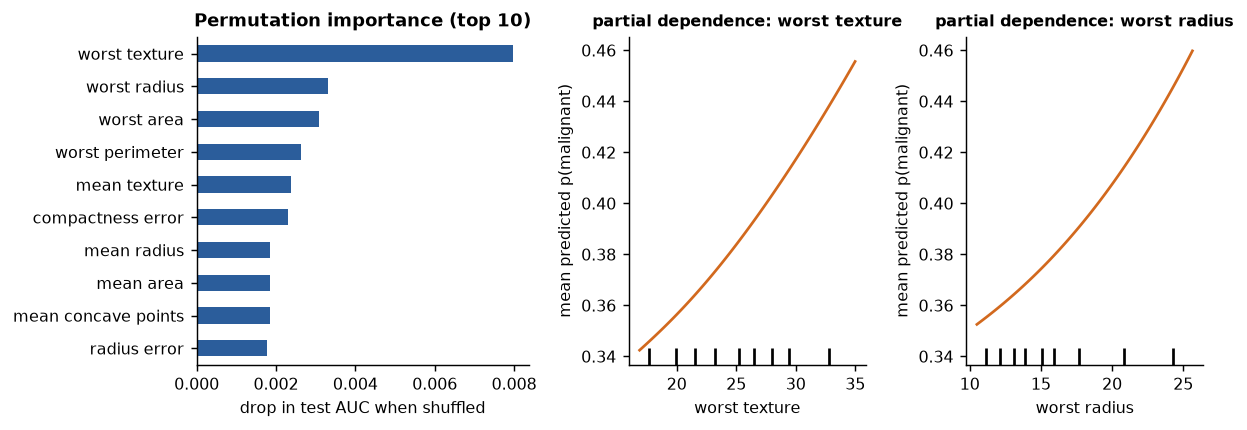

In [26]:
# Explicaciones globales: importancia por permutación (caída del AUC de prueba al barajar una característica) y dependencia parcial de las dos características más importantes.
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
perm = permutation_importance(final_model, X_te, y_te, scoring="roc_auc", n_repeats=10, random_state=0)
imp = pd.Series(perm.importances_mean, index=Xc.columns).sort_values(ascending=False)
top = imp.index[:2].tolist()
print("permutation importance (mean drop in test AUC over 10 shuffles), top 8:"); print(imp.head(8).round(4).to_string())
print(f"features whose shuffling changes the AUC by less than 0.001: {(imp.abs() < 0.001).sum()} of 30")

fig, axes = plt.subplots(1, 3, figsize=(9.5, 3.4), gridspec_kw={"width_ratios": [1.4, 1, 1]})
imp.head(10)[::-1].plot.barh(ax=axes[0], color=BLUE); axes[0].set_xlabel("drop in test AUC when shuffled"); axes[0].set_title("Permutation importance (top 10)")
PartialDependenceDisplay.from_estimator(final_model, X_te, features=top, ax=axes[1:], line_kw={"color": ORANGE})
for ax, f in zip(axes[1:], top): ax.set_title(f"partial dependence: {f}", fontsize=9); ax.set_ylabel("mean predicted p(malignant)")
fig.tight_layout()

<p class="caption"><b>Figura 11.</b> Izquierda: importancia por permutación de las diez características más influyentes —la caída media del AUC de prueba cuando se baraja la columna—. Las medidas "worst" (los valores más grandes entre los núcleos de un aspirado) de textura, radio, área y perímetro encabezan la lista; todas las caídas son inferiores a 0.01 porque el AUC está cerca de su techo y las características son redundantes, y 8 de 30 pueden barajarse prácticamente sin efecto. Derecha: dependencia parcial respecto de "worst texture" y "worst radius" —ambas aumentan de forma monótona, como predice la patología—; el rango es estrecho porque la curva promedia sobre las demás características.</p>

Ambas herramientas fallan con características correlacionadas —las variables correlacionadas con una característica barajada quedan intactas, de modo que una característica duplicada parece poco importante; la dependencia parcial evalúa el modelo en combinaciones que nunca ocurren— y ambas explican el <em>modelo</em>, no la <em>enfermedad</em>.

**Una explicación local y la alternativa interpretable.** Para un modelo lineal, la salida de un paciente se descompone de manera exacta: el logit es $\beta_0 + \sum_j \beta_j z_j$, así que cada característica estandarizada contribuye con $\beta_j z_j$. Para una caja negra, LIME y SHAP ajustan un sustituto local o calculan atribuciones basadas en teoría de juegos —aproximaciones—. Rudin sostiene que en las decisiones de alto riesgo la aproximación es el problema: puede equivocarse justo donde importa, y con datos tabulares un modelo interpretable suele desempeñarse igual de bien.<sup class="c"><a href="#r22">[22]</a></sup> La celda pone a prueba esta afirmación: ajusta la regresión logística de la Unidad 2, compara su AUC con el de la caja negra y explica de manera exacta a un paciente limítrofe.

logistic regression (C = 0.1): test AUC 0.995, Brier 0.028  |  black box: AUC 0.997, Brier 0.023
patient 208: true class benign; black-box p = 0.50; logistic p = 0.41
log-odds = intercept -0.44 + sum of contributions 0.07 = -0.37


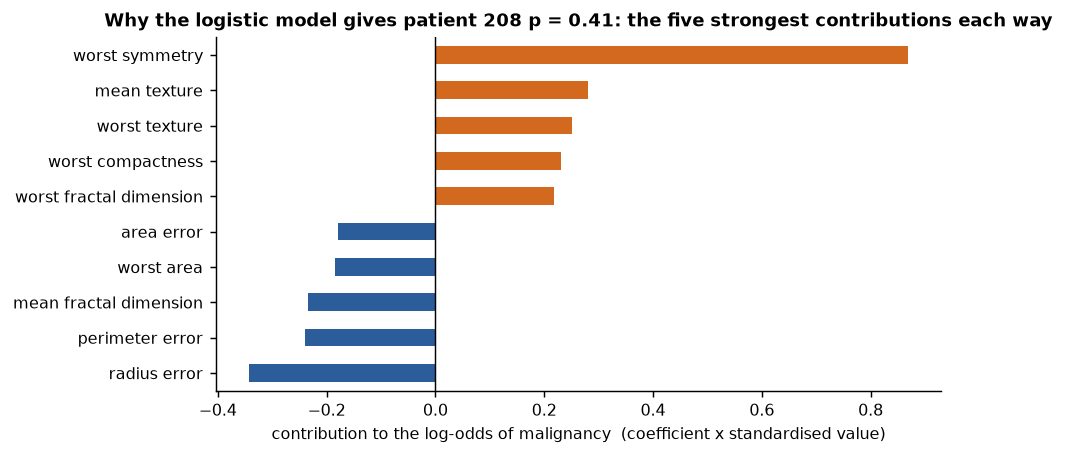

In [27]:
# Un modelo interpretable junto a la caja negra, y una explicación local exacta de un paciente de prueba limítrofe.
from sklearn.linear_model import LogisticRegression
logit_model = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)), {"logisticregression__C": [0.01, 0.03, 0.1, 0.3, 1]}, cv=outer, scoring="roc_auc").fit(X_tr, y_tr)
p_lr = logit_model.predict_proba(X_te)[:, 1]
print(f"logistic regression (C = {logit_model.best_params_['logisticregression__C']}): test AUC {roc_auc_score(y_te, p_lr):.3f}, Brier {brier_score_loss(y_te, p_lr):.3f}  |  black box: AUC {auc_te:.3f}, Brier {brier_te:.3f}")
scaler, lr = logit_model.best_estimator_.steps[0][1], logit_model.best_estimator_.steps[1][1]
i = int(np.argmin(np.abs(p_te - 0.5)))                                                # el paciente de prueba más cercano a la frontera de decisión
z = scaler.transform(X_te.iloc[[i]])[0]
contrib = pd.Series(lr.coef_[0] * z, index=Xc.columns).sort_values()
print(f"patient {X_te.index[i]}: true class {'malignant' if y_te_arr[i] == 1 else 'benign'}; black-box p = {p_te[i]:.2f}; logistic p = {p_lr[i]:.2f}")
print(f"log-odds = intercept {lr.intercept_[0]:.2f} + sum of contributions {contrib.sum():.2f} = {lr.intercept_[0] + contrib.sum():.2f}")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
shown = pd.concat([contrib.head(5), contrib.tail(5)])
shown.plot.barh(ax=ax, color=[BLUE if v < 0 else ORANGE for v in shown])
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("contribution to the log-odds of malignancy  (coefficient x standardised value)")
ax.set_title(f"Why the logistic model gives patient {X_te.index[i]} p = {p_lr[i]:.2f}: the five strongest contributions each way")
fig.tight_layout()

<p class="caption"><b>Figura 12.</b> Explicación local exacta de un paciente de prueba según la regresión logística: cada barra es un coeficiente multiplicado por el valor estandarizado del paciente, es decir, su contribución a las log-odds de malignidad. El paciente es aquel que la caja negra encontró más ambiguo (p = 0.50): una "worst symmetry" alta y una textura rugosa empujan hacia maligno, y las medidas pequeñas relacionadas con el tamaño hacia benigno; el modelo logístico se establece en 0.41, y la biopsia indicó benigno.</p>

El AUC de prueba de la regresión logística está a unas pocas milésimas del de la caja negra —el argumento de Rudin en miniatura—: con 30 características tabulares bien diseñadas, el modelo interpretable pierde poco y responde "¿por qué?" de manera exacta. La defensa de una caja negra debe basarse en una ganancia medible en la población de <em>despliegue</em>. Donde la ganancia existe —imágenes, señales, texto, donde las características se aprenden (Unidad 8)—, las explicaciones post hoc como los mapas de saliencia son la única opción y son hipótesis sobre el modelo, no razones.

### 5.4 La privacidad revisitada: desidentificación, datos sintéticos, aprendizaje federado, privacidad diferencial

La Unidad 1, Sección 7.2, mostró que eliminar los identificadores no anonimiza. Tres técnicas adicionales responden preguntas distintas. **Datos sintéticos**: un modelo generativo entrenado con los registros reales muestrea registros nuevos con la misma distribución conjunta; un generador ajustado con pocos registros puede memorizarlos y, sin una garantía formal, su privacidad es una afirmación empírica que debe ponerse a prueba mediante ataques de inferencia de pertenencia (membership inference). El **aprendizaje federado** permite que varios hospitales entrenen un solo modelo sin compartir registros: en el <em>promediado federado</em> (federated averaging) de McMahan y colaboradores, cada sitio entrena localmente y envía solo parámetros a un servidor, que los promedia ponderándolos por el tamaño muestral y devuelve el promedio, ronda tras ronda.<sup class="c"><a href="#r23">[23]</a></sup> Rieke y colaboradores revisan su uso en salud digital y sus problemas abiertos: sitios con distribuciones distintas, calidad de datos desigual y parámetros que pueden, a su vez, filtrar información sobre los registros de entrenamiento —el aprendizaje federado es una herramienta de gobernanza, no una garantía de privacidad—.<sup class="c"><a href="#r24">[24]</a></sup> La celda simula una ronda con tres "hospitales" obtenidos a partir del conjunto de entrenamiento.

In [28]:
# Promediado federado, una ronda: tres hospitales ajustan localmente una regresión logística; solo viajan coeficientes y estadísticas resumen.
rng = np.random.default_rng(0)
site = rng.choice(3, size=len(y_tr), p=[0.5, 0.3, 0.2])                        # tres hospitales de tamaño desigual
Xtr_arr, ytr_arr = X_tr.to_numpy(), y_tr.to_numpy()
# paso 1: cada sitio envía solo su n, las medias y las varianzas de las características; el servidor construye un escalador global (ningún registro sale del sitio)
ns = np.array([(site == s).sum() for s in range(3)])
means = np.array([Xtr_arr[site == s].mean(0) for s in range(3)]); vars_ = np.array([Xtr_arr[site == s].var(0) for s in range(3)])
mu = (ns[:, None] * means).sum(0) / ns.sum()
sigma = np.sqrt(((ns[:, None] * (vars_ + (means - mu) ** 2)).sum(0)) / ns.sum())
# paso 2: cada sitio ajusta localmente sobre datos escalados globalmente y envía los coeficientes; el servidor los promedia ponderados por n
local = [LogisticRegression(C=0.1, max_iter=5000).fit((Xtr_arr[site == s] - mu) / sigma, ytr_arr[site == s]) for s in range(3)]
coef_fed = sum(n * m.coef_[0] for n, m in zip(ns, local)) / ns.sum(); b_fed = sum(n * m.intercept_[0] for n, m in zip(ns, local)) / ns.sum()
Zte = (X_te.to_numpy() - mu) / sigma
p_fed = 1 / (1 + np.exp(-(Zte @ coef_fed + b_fed)))
central = LogisticRegression(C=0.1, max_iter=5000).fit((Xtr_arr - mu) / sigma, ytr_arr)
rows = [{"model": f"hospital {s + 1} alone (n = {ns[s]})", "test AUC": roc_auc_score(y_te, local[s].predict_proba(Zte)[:, 1])} for s in range(3)]
rows += [{"model": "federated average (1 round)", "test AUC": roc_auc_score(y_te, p_fed)}, {"model": "centralised (all data pooled)", "test AUC": roc_auc_score(y_te, central.predict_proba(Zte)[:, 1])}]
pd.DataFrame(rows).set_index("model").round(4)

,test AUC
model,
hospital 1 alone (n = 192),0.9935
hospital 2 alone (n = 127),0.9901
hospital 3 alone (n = 107),0.9910
federated average (1 round),0.9933
centralised (all data pooled),0.9945


El modelo federado, construido sin que ningún registro saliera de su hospital, iguala al centralizado con una diferencia de unas pocas milésimas de AUC y supera al modelo propio del hospital más pequeño. Bastó una ronda porque los sitios comparten una distribución y el modelo es convexo; las federaciones reales necesitan muchas rondas. Lo que sí viajó —treinta medias, treinta varianzas, treinta y un coeficientes por sitio— plantea la pregunta que responde la privacidad diferencial.

La **privacidad diferencial** es la única de estas técnicas con una garantía matemática: un algoritmo aleatorizado $\mathcal{M}$ es $\varepsilon$-diferencialmente privado si, para todo par de conjuntos de datos $D, D'$ que difieren en un registro y todo conjunto de salidas $S$, $P(\mathcal{M}(D) \in S) \le e^{\varepsilon}\, P(\mathcal{M}(D') \in S)$ —la salida apenas cambia según esté o no una persona cualquiera en los datos—.<sup class="c"><a href="#r25">[25]</a></sup> El mecanismo básico agrega ruido calibrado según la <em>sensibilidad</em> de la consulta, lo máximo que un registro puede cambiarla: para un conteo, ruido de Laplace de escala $1/\varepsilon$. El presupuesto $\varepsilon$ se gasta con cada consulta y la garantía se compone. La celda publica un conteo con tres presupuestos.

true count 53; one release at each budget: eps 0.1: 43.6, eps 1: 52.3, eps 10: 53.1


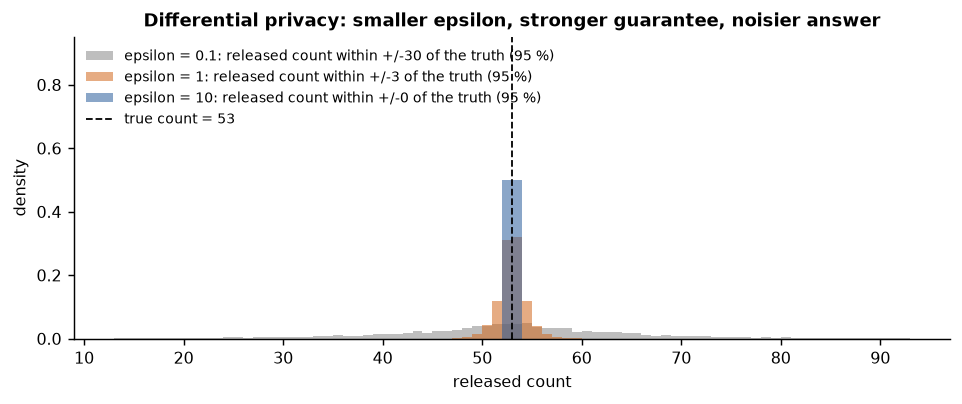

In [29]:
# El mecanismo de Laplace: publicar '¿cuántos casos malignos hay en el conjunto de prueba?' con tres presupuestos de privacidad.
true_count = int(y_te.sum())
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
for eps, col in [(0.1, GREY), (1.0, ORANGE), (10.0, BLUE)]:
    released = true_count + rng.laplace(0, 1 / eps, size=5000)                 # sensibilidad de un conteo = 1 -> escala 1/eps
    ax.hist(released, bins=np.arange(true_count - 40, true_count + 41, 1), density=True, alpha=0.55, color=col,
            label=f"epsilon = {eps:g}: released count within +/-{np.percentile(np.abs(released - true_count), 95):.0f} of the truth (95 %)")
ax.axvline(true_count, color="k", lw=1, ls="--", label=f"true count = {true_count}")
ax.set_ylim(0, 0.95); ax.set_xlabel("released count"); ax.set_ylabel("density"); ax.legend(frameon=False, fontsize=7.5, loc="upper left")
ax.set_title("Differential privacy: smaller epsilon, stronger guarantee, noisier answer")
fig.tight_layout()
print(f"true count {true_count}; one release at each budget: " + ", ".join(f"eps {e:g}: {true_count + rng.laplace(0, 1 / e):.1f}" for e in (0.1, 1, 10)))

<p class="caption"><b>Figura 13.</b> El conteo publicado por el mecanismo de Laplace con tres presupuestos. Con $\varepsilon = 10$ el valor casi siempre queda a una o dos unidades de la verdad y la garantía es débil; con $\varepsilon = 0.1$ la respuesta es inútil para un conjunto de datos de este tamaño, pero no se puede inferir la presencia de ningún individuo. El compromiso entre privacidad y utilidad se convierte en un solo número que puede presupuestarse y auditarse.</p>

La privacidad diferencial se aplica a estadísticas publicadas (el censo de los Estados Unidos desde 2020), al entrenamiento de modelos (ruido en las actualizaciones del gradiente) y a los generadores de datos sintéticos. Su costo es la exactitud, especialmente para grupos pequeños —justo donde las auditorías de equidad más necesitan precisión—; esa tensión es un problema abierto.

### 5.5 Gobernanza y regulación

Cuatro cuerpos de normas enmarcan el trabajo; la Unidad 1, Sección 7.5, introdujo los dos primeros.

**Protección de datos.** En Chile, la Ley 19.628 (1999) sobre protección de la vida privada; la Ley 20.584 (2012) sobre derechos de los pacientes, que establece la confidencialidad de la ficha clínica; y la Ley 21.719, publicada en diciembre de 2024 y vigente desde el 1 de diciembre de 2026, que alinea el régimen con el GDPR, crea la Agencia de Protección de Datos Personales con facultades de fiscalización y sanción, y clasifica los datos de salud y genéticos como sensibles (ver Recursos en línea). Los estudiantes que se titulen en 2027 ejercerán bajo la nueva ley desde su primer día.

**Regulación de dispositivos médicos.** El software que informa una decisión clínica es un dispositivo médico: regulado por la FDA en los Estados Unidos; en la Unión Europea, por el Reglamento de Dispositivos Médicos (2017/745) y la <strong>Ley de Inteligencia Artificial</strong> (AI Act, Reglamento 2024/1689), que clasifica la IA en dispositivos médicos como de <em>alto riesgo</em>, con obligaciones de gestión de riesgos, gobernanza de datos, documentación, transparencia, supervisión humana, exactitud, robustez y ciberseguridad, implementadas gradualmente en 2025–2027 (ver Recursos en línea); en Chile, por el Instituto de Salud Pública (ISP) bajo el Código Sanitario y el Decreto 825/1998, con una política nacional de IA y un proyecto de ley de IA que sigue la estructura europea basada en el riesgo. Un modelo desplegado sin registro sanitario es un dispositivo médico no registrado, sea cual sea su AUC.

**Orientación ética.** La guía de la OMS de 2021 establece seis principios —autonomía; bienestar, seguridad e interés público; transparencia, explicabilidad e inteligibilidad; responsabilidad y rendición de cuentas; inclusividad y equidad; IA receptiva y sostenible— (ver Recursos en línea). Cada uno se concreta aquí: ficha del modelo y estándares de reporte (transparencia), curva de decisión y umbral basado en costos (seguridad), auditoría de equidad (equidad), privacidad diferencial y consentimiento (autonomía), la lista de verificación (rendición de cuentas).

**Integridad en la investigación y ciencia abierta.** Los <strong>principios FAIR</strong> piden que los datos y metadatos sean localizables, accesibles, interoperables y reutilizables (Findable, Accessible, Interoperable, Reusable) —identificadores persistentes, metadatos ricos, acceso con condiciones claras, vocabularios estándar—, bajo controles de acceso cuando son sensibles.<sup class="c"><a href="#r26">[26]</a></sup> Las diez reglas de Sandve y colaboradores para la investigación computacional reproducible —registrar cómo se produjo cada resultado, archivar las versiones de los programas, registrar las semillas, conservar los datos crudos detrás de los gráficos, dar acceso público a los scripts— son los principios de diseño de este notebook: cada número es reproducido por una celda con una semilla fija, y el notebook es público.<sup class="c"><a href="#r27">[27]</a></sup> La autoría sigue la misma lógica: quien contribuyó de manera sustancial y puede asumir la responsabilidad es autor. Un modelo entrenado por un estudiante con datos de un hospital y publicado sin conocimiento del hospital viola a la vez el acuerdo de uso de datos, la aprobación ética y las normas de autoría.

### 5.6 Una lista de verificación profesional para el bioingeniero que despliega un sistema que aprende

El curso cierra con dieciséis preguntas que hay que responder antes, durante y después de desplegar cualquier sistema que aprenda de datos sobre personas.

<div class="box key"><h4>Antes de construir</h4>
<ol>
<li><strong>Propósito.</strong> ¿Qué decisión informará el sistema, quién la toma y qué le ocurre a un paciente cuando se equivoca en cada dirección?</li>
<li><strong>Etiqueta.</strong> ¿Mide la etiqueta lo que pretendemos, o un sustituto (proxy) que codifica una inequidad? ¿Quién la asignó y con qué tasa de error?</li>
<li><strong>Base legal y consentimiento.</strong> ¿Bajo qué base legal y qué aprobación ética se usan los datos, y está este proyecto dentro de ese propósito?</li>
<li><strong>Representatividad.</strong> ¿De qué sitios, escáneres, años y poblaciones provienen los datos; qué grupos están ausentes?</li>
</ol></div>

<div class="box key"><h4>Durante la construcción</h4>
<ol start="5">
<li><strong>Fuga de datos.</strong> ¿Está bloqueado el conjunto de prueba, está cada paso de preprocesamiento dentro de la validación cruzada, se eligen los hiperparámetros y la familia en bucles anidados?</li>
<li><strong>Calibración y umbral.</strong> ¿Son las salidas probabilidades calibradas, a qué prevalencia, y se eligió el umbral a partir de los costos clínicos junto con los clínicos?</li>
<li><strong>Utilidad.</strong> ¿Muestra una curva de decisión un beneficio neto sobre las estrategias por defecto en todo el rango de umbrales plausibles?</li>
<li><strong>Equidad.</strong> ¿Qué criterio es apropiado y por qué; lo satisface el modelo en los subgrupos que importan, con intervalos de confianza?</li>
<li><strong>Explicación.</strong> ¿Podría un modelo interpretable hacer el trabajo? Si no, ¿qué explicaciones recibirán los usuarios y cómo se validaron?</li>
<li><strong>Privacidad.</strong> Datos seudonimizados, acceso registrado, modelo verificado en cuanto a memorización; ¿se justifica un entrenamiento federado o con privacidad diferencial?</li>
</ol></div>

<div class="box key"><h4>Antes y después del despliegue</h4>
<ol start="11">
<li><strong>Validación externa.</strong> ¿Se ha evaluado el modelo con datos del sitio y del período de despliegue?</li>
<li><strong>Documentación.</strong> ¿Ficha del modelo, etiqueta de datos del modelo (model facts) y un reporte que siga TRIPOD+AI, DECIDE-AI o CONSORT-AI?</li>
<li><strong>Regulación.</strong> ¿Es un dispositivo médico, registrado ante el ISP (o la FDA / un organismo notificado de la UE), que cumple las obligaciones de alto riesgo de la Ley de IA cuando corresponde?</li>
<li><strong>Supervisión humana y los cinco correctos.</strong> ¿Quién puede anularlo, cómo se registra eso, y llega a la persona correcta en el formato correcto en el momento correcto?</li>
<li><strong>Monitoreo y retiro.</strong> ¿Quién monitorea el desempeño, la calibración y las tasas de error por subgrupo; qué gatilla el reentrenamiento o el retiro; quién rinde cuentas?</li>
<li><strong>Reproducibilidad.</strong> ¿Están archivados el código, las semillas, el entorno y, cuando sea lícito, los datos, de modo que cada número pueda regenerarse?</li>
</ol></div>

Un sistema para el cual no se pueden responder estas preguntas no está listo, sea cual sea su AUC. Los métodos de las Unidades 2–8 hacen posibles las respuestas; esta unidad trata de la obligación de darlas.

## 6. Un panorama de las aplicaciones actuales, para el Taller 6

Para el Taller 6, quince sistemas o estudios, cada uno con una referencia principal y su <em>nivel de evidencia</em> (Sección 3.3). Elige una fila, lee el artículo con la lista de verificación de la Sección 5.6 e informa cuáles de sus preguntas responde el artículo.

| # | Dominio | Sistema o estudio | Qué hace (método de este curso) | Nivel de evidencia | Ref. |
|---|---|---|---|---|---|
| 1 | Imágenes — oftalmología | IDx-DR, tamizaje autónomo de retinopatía diabética | Clasificador CNN sobre fotografías de fondo de ojo (U8) | Ensayo pivotal prospectivo en atención primaria; autorización de la FDA para uso autónomo, 2018 | <sup class="c"><a href="#r28">[28]</a></sup> |
| 2 | Imágenes — radiología, patología, dermatología | Clasificadores de aprendizaje profundo comparados con especialistas | CNN, aprendizaje por transferencia (U8) | Metaanálisis de 82 estudios: equivalencia en promedio; 25 con validación externa; alto riesgo de sesgo | <sup class="c"><a href="#r10">[10]</a></sup> |
| 3 | Imágenes — dermatología | Clasificación de lesiones cutáneas a nivel de dermatólogo | CNN ajustada (fine-tuning) a partir de ImageNet | Estudio retrospectivo de lectores frente a dermatólogos sobre lesiones confirmadas por biopsia | <sup class="c"><a href="#r28">[28]</a></sup> |
| 4 | Imágenes — todas las especialidades | Calidad del diseño de los estudios de IA frente a clínicos | — | Revisión sistemática: 81 estudios no aleatorizados, 2 ensayos; resúmenes que exageran | <sup class="c"><a href="#r11">[11]</a></sup> |
| 5 | Señales — cardiología, dispositivos portátiles | ECG con IA y clasificación del ritmo con relojes inteligentes | CNN sobre ECG y fotopletismografía (U6/U8) | Grandes validaciones retrospectivas; dispositivos portátiles con autorización de la FDA; evaluación prospectiva de las notificaciones de relojes inteligentes | <sup class="c"><a href="#r28">[28]</a></sup> |
| 6 | Predicción con registros clínicos electrónicos (EHR) | Modelo propietario de sepsis desplegado en cientos de hospitales de EE. UU. | Regresión logística penalizada sobre variables del registro (U2) | Validación externa tras el despliegue: sensibilidad 33 %, VPP 12 % — muy por debajo de lo declarado en el desarrollo | <sup class="c"><a href="#r33">[33]</a></sup> |
| 7 | Predicción con EHR | Sepsis Watch (Duke University Hospital) con una etiqueta de datos del modelo | Modelo profundo sobre datos del registro en flujo continuo, con una etiqueta de datos de una página | Desplegado con monitoreo prospectivo; el ejemplo de referencia de documentación orientada al usuario | <sup class="c"><a href="#r31">[31]</a></sup> |
| 8 | Predicción con EHR | Predicción de deterioro, reingreso y mortalidad | Regresión, ensambles de árboles, redes profundas (U2, U4, U6) | Revisión: sólidos resultados retrospectivos; las barreras son los flujos de datos, el flujo de trabajo y la evaluación de desenlaces | <sup class="c"><a href="#r30">[30]</a></sup> |
| 9 | Predicción con EHR | Modelos diagnósticos y pronósticos de COVID-19 | Mayormente regresión logística y ensambles de árboles (U2, U4) | Revisión viva: cientos de modelos, casi todos con alto riesgo de sesgo, ninguno recomendado | <sup class="c"><a href="#r19">[19]</a></sup> |
| 10 | Salud poblacional | Algoritmo comercial que asigna recursos de gestión de cuidados | Regresión que predice el costo como sustituto de la necesidad (U2) | Desplegado a gran escala; una auditoría encontró un gran sesgo racial a través de la etiqueta | <sup class="c"><a href="#r29">[29]</a></sup> |
| 11 | Texto clínico | Extracción de información de notas clínicas | Pipelines basados en reglas y en bolsa de palabras (Sección 2.8) | Revisión de 263 estudios; mayormente de una sola institución, rara vez con validación externa | <sup class="c"><a href="#r7">[7]</a></sup> |
| 12 | Imágenes multicéntricas | Consorcios de aprendizaje federado para imágenes médicas | Promediado federado entre hospitales (Sección 5.4) | Revisión de los primeros despliegues; problemas abiertos de heterogeneidad y privacidad | <sup class="c"><a href="#r24">[24]</a></sup> |
| 13 | Biología estructural | Predicción de estructura de proteínas con AlphaFold2 | Red de atención sobre secuencias y alineamientos (BGM324) | Evaluación ciega (CASP14); exactitud cercana a la experimental; base de datos pública de estructuras | <sup class="c"><a href="#r34">[34]</a></sup> |
| 14 | Descubrimiento de fármacos | Clasificación QSAR de inhibidores de ureasa y de TRPV1 | Ensambles de árboles sobre descriptores; reposicionamiento; docking y simulación (U4; BGM324) | Estudios computacionales con validación cruzada; candidatos priorizados para ensayo | <sup class="c"><a href="#r8">[8]</a>,<a href="#r9">[9]</a></sup> |
| 15 | Modelos de lenguaje | Med-PaLM: gran modelo de lenguaje para responder preguntas médicas | Modelo de lenguaje Transformer (U1 §2.6) | Evaluación con benchmarks y calificación de médicos; sin evaluación clínica | <sup class="c"><a href="#r35">[35]</a></sup> |

Tres patrones: el nivel de evidencia es independiente de la sofisticación del método —el modelo más simple (fila 6) es el más ampliamente desplegado y el que se demostró que falla—; los sistemas con evidencia prospectiva (filas 1, 5, 7) son acotados y se evaluaron a nivel de la decisión; y las auditorías y revisiones (filas 4, 6, 9, 10) son las más instructivas, porque muestran qué preguntas de la lista de verificación no se plantearon.

## 7. Resumen del curso

Ahora deberías ser capaz de explicar, sin apuntes:

- KDD y CRISP-DM; las cuatro familias de tareas; por qué la mayor parte del trabajo ocurre antes y después del algoritmo.
- Soporte, confianza, lift; la unión y la poda de Apriori; por qué muchas reglas producen reglas espurias y cómo una distribución nula por permutación y Bonferroni las ponen en evidencia.
- Los bosques de aislamiento ("diferente" no es "enfermo"); la bolsa de palabras y lo que pierde.
- Las cinco tareas de imágenes; qué hace diferentes a las imágenes médicas; Dice e IoU; la base de evidencia; cómo un cambio de escáner quiebra un modelo validado honestamente.
- De MYCIN e INTERNIST-1 al apoyo a la decisión; los cinco correctos; las razones de verosimilitud y el nomograma de Fagan; por qué la probabilidad de un clasificador está ligada a la prevalencia de su entrenamiento.
- El modelo diagnóstico honesto: validación cruzada anidada, calibración, curva de decisión, umbral basado en costos, verificación por subgrupos, ficha del modelo; los tres estándares de reporte; por qué la mayoría de los modelos nunca llega a la práctica.
- El ciclo de vida de los datos; los tres criterios de equidad y el resultado de imposibilidad; la explicación y sus límites; los datos sintéticos, el promediado federado, la privacidad diferencial; el marco legal, los principios de la OMS, FAIR, la reproducibilidad; la lista de verificación de dieciséis preguntas.

## 8. Autoevaluación

<details><summary>1. ¿Qué parte del curso sirve a cada adjetivo de KDD —válido, novedoso, útil, comprensible— y cuál de ellos no cumple por defecto una caja negra con AUC 0.99?</summary>Válido: Suplemento S1. Novedoso: conocimiento del dominio (Sección 2.1). Útil: curvas de decisión y los cinco correctos (Secciones 4.2, 4.4). Comprensible: Sección 5.3 —el que la caja negra no cumple por defecto—.</details>

<details><summary>2. De 200 pacientes, 80 tienen hipertensión, 60 toman una estatina y 36 ambas cosas. ¿Soporte, confianza y lift de "hipertensión ⇒ estatina"?</summary>Soporte 36/200 = 0.18; confianza 36/80 = 0.45; lift 0.45/0.30 = 1.5: una asociación positiva, cuya significancia requiere una prueba y cuya causalidad no puede conocerse a partir de estos datos.</details>

<details><summary>3. ¿Por qué se podó {HTN, DM, ACEi} sin contarlo, y qué cambia si no se poda?</summary>Su subconjunto {DM, ACEi} no era frecuente, así que por la propiedad Apriori no puede ser frecuente. Sin poda el resultado no cambia, pero se cuentan muchos más candidatos por nivel —y en una base de datos real el número de candidatos es lo que vuelve intratable el problema—.</details>

<details><summary>4. Un colega mina 10,000 pares fármaco–evento e informa cada par con lift superior a 2. ¿Qué está mal?</summary>Con 10,000 pruebas, muchos pares superan cualquier lift fijo por azar, especialmente los poco frecuentes (Figura 3). Hay que poner a prueba cada par, corregir por el número de pruebas (Bonferroni o tasa de falsos descubrimientos), tratar con cautela los pares poco frecuentes y confirmar los sobrevivientes en datos independientes y mediante revisión clínica.</details>

<details><summary>5. |S| = 500 píxeles, |G| = 400, solapamiento 300. Calcula Dice e IoU y verifica la identidad.</summary>Dice = 600/900 = 0.667; IoU = 300/600 = 0.500; 2 × 0.5/1.5 = 0.667. ✓</details>

<details><summary>6. En la Figura 6 la exactitud colapsó con un "escáner distinto", aunque las exactitudes de validación cruzada y de prueba coincidían. ¿Por qué ninguna advirtió el problema?</summary>Ambas se calcularon sobre la distribución de entrenamiento y no dicen nada sobre otra. Solo la evaluación con datos del otro escáner, o el entrenamiento con aumento de datos que incluya la variación, aborda el cambio.</details>

<details><summary>7. Sensibilidad 0.95, especificidad 0.80: ¿LR⁺ y probabilidad post-test tras un resultado positivo con probabilidad pre-test de 0.10 y de 0.50?</summary>LR⁺ = 0.95/0.20 = 4.75. Odds 0.111 → 0.528 → p = 0.35. Odds 1 → 4.75 → p = 0.83. El mismo resultado da 35 % u 83 % según a quién se le hizo la prueba.</details>

<details><summary>8. El código eligió la familia con el AUC más alto en los pliegues externos. ¿Es insesgado ese AUC? ¿Y el AUC del conjunto de prueba?</summary>El AUC externo seleccionado es levemente optimista —el máximo de tres estimaciones ruidosas—. El AUC del conjunto de prueba es insesgado para todo el procedimiento, incluida la selección, porque el conjunto de prueba no participó en ninguna elección.</details>

<details><summary>9. En la Figura 9, ¿qué significa un beneficio neto por encima de "biopsy everyone" con p_t = 0.20, y por qué todas las curvas se juntan cerca de p_t = 0?</summary>Con p_t = 0.20 un clínico acepta cuatro biopsias innecesarias por cada cáncer; una curva más alta significa que actuar según el modelo encuentra más cánceres, descontado el daño, a esa tasa de intercambio. Cerca de p_t = 0 un falso positivo no conlleva daño, así que biopsiar a todos es óptimo.</details>

<details><summary>10. El grupo de mayor edad fue marcado con mucha más frecuencia. ¿Es inequitativo? ¿Qué criterio falla, cuáles se cumplen, y por qué no los tres?</summary>La paridad demográfica falla, de manera apropiada, porque la malignidad es más común en el grupo de mayor edad; las probabilidades igualadas y la calibración dentro de los grupos se cumplen aproximadamente. Con tasas base distintas y un clasificador imperfecto, la calibración y la igualdad de las tasas de error no pueden cumplirse ambas exactamente, de modo que una elección justificada es inevitable.</details>

<details><summary>11. En la celda federada, ¿qué salió de cada hospital, y por qué la privacidad diferencial sigue siendo relevante?</summary>El tamaño muestral, 30 medias, 30 varianzas y 31 coeficientes —funciones de los datos de los pacientes que pueden filtrar información sobre individuos (la media de un sitio pequeño se desplaza con un solo paciente extremo; los coeficientes pueden memorizar registros poco frecuentes)—. Se necesita una garantía formal sobre las cantidades transmitidas para que la federación preserve la privacidad en lugar de ser simplemente local en cuanto a los datos.</details>

<details><summary>12. Un hospital quiere que el modelo del proyecto integrador se despliegue el próximo mes. ¿Qué cuatro preguntas de la lista de verificación responde este notebook de manera inadecuada?</summary>Validación externa (P11): solo validación interna con datos de un solo sitio de la década de 1990. Equidad (P8): no hay variables demográficas. Regulación (P13): un dispositivo médico sin registro en el ISP. Supervisión y monitoreo (P14–15): no hay un plan para anulaciones, monitoreo ni retiro. La base legal para los datos locales (P3) es una quinta.</details>

## Glosario

<dl class="gloss">
<dt>Propiedad Apriori (Apriori property)</dt><dd>Todo subconjunto de un conjunto de ítems frecuente es frecuente; la base del paso de poda.</dd>
<dt>Regla de asociación (association rule)</dt><dd>A ⇒ B entre conjuntos de ítems disjuntos; coocurrencia, no causalidad.</dd>
<dt>Corrección de Bonferroni (Bonferroni correction)</dt><dd>Dividir el nivel de significancia por el número de pruebas realizadas.</dd>
<dt>Puntaje de Brier (Brier score)</dt><dd>Diferencia cuadrática media entre la probabilidad predicha y el desenlace 0/1; más bajo es mejor.</dd>
<dt>Calibración (calibration)</dt><dd>Concordancia entre las probabilidades predichas y las frecuencias observadas.</dd>
<dt>CDSS (clinical decision support system)</dt><dd>Sistema de apoyo a la decisión clínica.</dd>
<dt>Confianza / soporte / lift (confidence / support / lift)</dt><dd>P(B | A) / P(A ∪ B) / P(A, B) dividido por P(A)P(B), estimados a partir de las frecuencias de las transacciones; el lift es 1 bajo independencia.</dd>
<dt>CRISP-DM</dt><dd>Comprensión del negocio, comprensión de los datos, preparación de los datos, modelado, evaluación, despliegue.</dd>
<dt>Análisis de curva de decisión (decision-curve analysis)</dt><dd>Beneficio neto de un modelo a lo largo de las probabilidades umbral, frente a tratar a todos y a no tratar a nadie.</dd>
<dt>Paridad demográfica / probabilidades igualadas / calibración dentro de los grupos (demographic parity / equalised odds / calibration within groups)</dt><dd>Igual tasa de decisiones positivas / igual sensibilidad e igual tasa de falsos positivos / igual significado de una probabilidad predicha entre los grupos; incompatibles en general cuando las tasas base difieren.</dd>
<dt>Dice / IoU</dt><dd>2|S ∩ G|/(|S| + |G|) y |S ∩ G|/|S ∪ G|; Dice = 2 IoU/(1 + IoU).</dd>
<dt>Privacidad diferencial (differential privacy)</dt><dd>La distribución de las salidas cambia a lo más en un factor e^ε cuando se agrega o se elimina un registro.</dd>
<dt>Cambio de dominio (domain shift)</dt><dd>Un cambio en la distribución de las entradas entre el entrenamiento y el despliegue.</dd>
<dt>Aprendizaje federado (federated learning)</dt><dd>Entrenamiento entre poseedores de datos mediante el intercambio de parámetros en lugar de registros.</dd>
<dt>Bosque de aislamiento (isolation forest)</dt><dd>Detector de anomalías: los puntos aislados con pocas divisiones aleatorias son anómalos. No necesita etiquetas.</dd>
<dt>KDD (knowledge discovery in databases)</dt><dd>Descubrimiento de conocimiento en bases de datos; la minería de datos es uno de sus pasos.</dd>
<dt>Razón de verosimilitud (likelihood ratio)</dt><dd>LR⁺ = sensibilidad/(1 − especificidad); LR⁻ = (1 − sensibilidad)/especificidad; multiplica las odds pre-test.</dd>
<dt>Ficha del modelo (model card)</dt><dd>Declaración estructurada de los detalles de un modelo, su uso previsto, sus datos, sus métricas por subgrupo y sus advertencias.</dd>
<dt>Validación cruzada anidada (nested cross-validation)</dt><dd>Bucle interno para los hiperparámetros dentro de cada pliegue de entrenamiento de un bucle externo para el desempeño.</dd>
<dt>Beneficio neto (net benefit)</dt><dd>TP/n − FP/n × p_t/(1 − p_t).</dd>
<dt>Dependencia parcial / importancia por permutación (partial dependence / permutation importance)</dt><dd>Predicción promedio a medida que varía una característica / pérdida de desempeño cuando se baraja una característica.</dd>
<dt>TRIPOD+AI, DECIDE-AI, CONSORT-AI</dt><dd>Estándares de reporte para el desarrollo y la validación de modelos, la evaluación clínica temprana y los ensayos aleatorizados con un componente de IA.</dd>
</dl>

## Referencias y lecturas recomendadas

<ol class="refs">
<li id="r1">Fayyad U, Piatetsky-Shapiro G, Smyth P. From data mining to knowledge discovery in databases. <em>AI Magazine</em>. 1996;17(3):37–54. <a href="https://ojs.aaai.org/aimagazine/index.php/aimagazine/article/view/1230">ojs.aaai.org/aimagazine/…/view/1230</a> (página de la editorial; el DOI 10.1609/aimag.v17i3.1230 indicado por la editorial no está indexado en Crossref y no pudo verificarse al momento de escribir este texto)</li>
<li id="r2">Schröer C, Kruse F, Gómez JM. A systematic literature review on applying CRISP-DM process model. <em>Procedia Comput Sci</em>. 2021;181:526–534. <a href="https://doi.org/10.1016/j.procs.2021.01.199">doi:10.1016/j.procs.2021.01.199</a></li>
<li id="r3">Agrawal R, Imieliński T, Swami A. Mining association rules between sets of items in large databases. <em>Proc 1993 ACM SIGMOD Int Conf Management of Data</em>. 1993:207–216. <a href="https://doi.org/10.1145/170035.170072">doi:10.1145/170035.170072</a></li>
<li id="r4">Agrawal R, Srikant R. Fast algorithms for mining association rules in large databases. <em>Proc 20th Int Conf Very Large Data Bases (VLDB 1994)</em>. 1994:487–499. <a href="https://www.vldb.org/conf/1994/P487.PDF">vldb.org/conf/1994/P487.PDF</a> (artículo de congreso sin DOI)</li>
<li id="r5">Brin S, Motwani R, Silverstein C. Beyond market baskets: generalizing association rules to correlations. <em>Proc 1997 ACM SIGMOD Int Conf Management of Data</em>. 1997:265–276. <a href="https://doi.org/10.1145/253260.253327">doi:10.1145/253260.253327</a></li>
<li id="r6">Liu FT, Ting KM, Zhou Z-H. Isolation forest. <em>Proc 8th IEEE Int Conf Data Mining (ICDM 2008)</em>. 2008:413–422. <a href="https://doi.org/10.1109/ICDM.2008.17">doi:10.1109/ICDM.2008.17</a></li>
<li id="r7">Wang Y, Wang L, Rastegar-Mojarad M, et al. Clinical information extraction applications: a literature review. <em>J Biomed Inform</em>. 2018;77:34–49. <a href="https://doi.org/10.1016/j.jbi.2017.11.011">doi:10.1016/j.jbi.2017.11.011</a></li>
<li id="r8">Morales N, Valdés-Muñoz E, González J, et al. Machine learning-driven classification of urease inhibitors leveraging physicochemical properties as effective filter criteria. <em>Int J Mol Sci</em>. 2024;25(8):4303. <a href="https://doi.org/10.3390/ijms25084303">doi:10.3390/ijms25084303</a></li>
<li id="r9">González J, Palma JM, Benso B, et al. Integrative computational approaches for TRPV1 ion channel inhibitor discovery: an integrated machine learning, drug repurposing and molecular simulation approach. <em>J Chem Inf Model</em>. 2025;65(17):8957–8968. <a href="https://doi.org/10.1021/acs.jcim.5c00991">doi:10.1021/acs.jcim.5c00991</a></li>
<li id="r10">Liu X, Faes L, Kale AU, et al. A comparison of deep learning performance against health-care professionals in detecting diseases from medical imaging: a systematic review and meta-analysis. <em>Lancet Digit Health</em>. 2019;1(6):e271–e297. <a href="https://doi.org/10.1016/S2589-7500(19)30123-2">doi:10.1016/S2589-7500(19)30123-2</a></li>
<li id="r11">Nagendran M, Chen Y, Lovejoy CA, et al. Artificial intelligence versus clinicians: systematic review of design, reporting standards, and claims of deep learning studies. <em>BMJ</em>. 2020;368:m689. <a href="https://doi.org/10.1136/bmj.m689">doi:10.1136/bmj.m689</a></li>
<li id="r12">Miller RA, Pople HE, Myers JD. INTERNIST-1, an experimental computer-based diagnostic consultant for general internal medicine. <em>N Engl J Med</em>. 1982;307(8):468–476. <a href="https://doi.org/10.1056/NEJM198208193070803">doi:10.1056/NEJM198208193070803</a></li>
<li id="r13">Fagan TJ. Nomogram for Bayes's theorem. <em>N Engl J Med</em>. 1975;293(5):257. <a href="https://doi.org/10.1056/NEJM197507312930513">doi:10.1056/NEJM197507312930513</a></li>
<li id="r14">Vickers AJ, Elkin EB. Decision curve analysis: a novel method for evaluating prediction models. <em>Med Decis Making</em>. 2006;26(6):565–574. <a href="https://doi.org/10.1177/0272989X06295361">doi:10.1177/0272989X06295361</a></li>
<li id="r15">Mitchell M, Wu S, Zaldivar A, et al. Model cards for model reporting. <em>Proc Conf Fairness, Accountability, and Transparency (FAT* 2019)</em>. 2019:220–229. <a href="https://doi.org/10.1145/3287560.3287596">doi:10.1145/3287560.3287596</a></li>
<li id="r16">Collins GS, Moons KGM, Dhiman P, et al. TRIPOD+AI statement: updated guidance for reporting clinical prediction models that use regression or machine learning methods. <em>BMJ</em>. 2024;385:e078378. <a href="https://doi.org/10.1136/bmj-2023-078378">doi:10.1136/bmj-2023-078378</a></li>
<li id="r17">Liu X, Cruz Rivera S, Moher D, Calvert MJ, Denniston AK; SPIRIT-AI and CONSORT-AI Working Group. Reporting guidelines for clinical trial reports for interventions involving artificial intelligence: the CONSORT-AI extension. <em>Nat Med</em>. 2020;26(9):1364–1374. <a href="https://doi.org/10.1038/s41591-020-1034-x">doi:10.1038/s41591-020-1034-x</a></li>
<li id="r18">Vasey B, Nagendran M, Campbell B, et al. Reporting guideline for the early-stage clinical evaluation of decision support systems driven by artificial intelligence: DECIDE-AI. <em>Nat Med</em>. 2022;28(5):924–933. <a href="https://doi.org/10.1038/s41591-022-01772-9">doi:10.1038/s41591-022-01772-9</a></li>
<li id="r19">Wynants L, Van Calster B, Collins GS, et al. Prediction models for diagnosis and prognosis of covid-19: systematic review and critical appraisal. <em>BMJ</em>. 2020;369:m1328. <a href="https://doi.org/10.1136/bmj.m1328">doi:10.1136/bmj.m1328</a></li>
<li id="r20">Chouldechova A. Fair prediction with disparate impact: a study of bias in recidivism prediction instruments. <em>Big Data</em>. 2017;5(2):153–163. <a href="https://doi.org/10.1089/big.2016.0047">doi:10.1089/big.2016.0047</a></li>
<li id="r21">Kleinberg J, Mullainathan S, Raghavan M. Inherent trade-offs in the fair determination of risk scores. <em>Proc 8th Innovations in Theoretical Computer Science Conference (ITCS 2017)</em>, LIPIcs 67:43:1–43:23. Preprint de arXiv. <a href="https://doi.org/10.48550/arXiv.1609.05807">doi:10.48550/arXiv.1609.05807</a></li>
<li id="r22">Rudin C. Stop explaining black box machine learning models for high stakes decisions and use interpretable models instead. <em>Nat Mach Intell</em>. 2019;1(5):206–215. <a href="https://doi.org/10.1038/s42256-019-0048-x">doi:10.1038/s42256-019-0048-x</a></li>
<li id="r23">McMahan HB, Moore E, Ramage D, Hampson S, Agüera y Arcas B. Communication-efficient learning of deep networks from decentralized data. <em>Proc 20th Int Conf Artificial Intelligence and Statistics (AISTATS 2017), PMLR</em>. 2017;54:1273–1282. <a href="https://proceedings.mlr.press/v54/mcmahan17a.html">proceedings.mlr.press/v54/mcmahan17a.html</a> (las actas de PMLR no tienen DOI)</li>
<li id="r24">Rieke N, Hancox J, Li W, et al. The future of digital health with federated learning. <em>npj Digit Med</em>. 2020;3:119. <a href="https://doi.org/10.1038/s41746-020-00323-1">doi:10.1038/s41746-020-00323-1</a></li>
<li id="r25">Dwork C, Roth A. The algorithmic foundations of differential privacy. <em>Found Trends Theor Comput Sci</em>. 2014;9(3–4):211–407. <a href="https://doi.org/10.1561/0400000042">doi:10.1561/0400000042</a></li>
<li id="r26">Wilkinson MD, Dumontier M, Aalbersberg IJ, et al. The FAIR Guiding Principles for scientific data management and stewardship. <em>Sci Data</em>. 2016;3:160018. <a href="https://doi.org/10.1038/sdata.2016.18">doi:10.1038/sdata.2016.18</a></li>
<li id="r27">Sandve GK, Nekrutenko A, Taylor J, Hovig E. Ten simple rules for reproducible computational research. <em>PLoS Comput Biol</em>. 2013;9(10):e1003285. <a href="https://doi.org/10.1371/journal.pcbi.1003285">doi:10.1371/journal.pcbi.1003285</a></li>
<li id="r28">Topol EJ. High-performance medicine: the convergence of human and artificial intelligence. <em>Nat Med</em>. 2019;25(1):44–56. <a href="https://doi.org/10.1038/s41591-018-0300-7">doi:10.1038/s41591-018-0300-7</a></li>
<li id="r29">Obermeyer Z, Powers B, Vogeli C, Mullainathan S. Dissecting racial bias in an algorithm used to manage the health of populations. <em>Science</em>. 2019;366(6464):447–453. <a href="https://doi.org/10.1126/science.aax2342">doi:10.1126/science.aax2342</a></li>
<li id="r30">Rajkomar A, Dean J, Kohane I. Machine learning in medicine. <em>N Engl J Med</em>. 2019;380(14):1347–1358. <a href="https://doi.org/10.1056/NEJMra1814259">doi:10.1056/NEJMra1814259</a></li>
<li id="r31">Sendak MP, Gao M, Brajer N, Balu S. Presenting machine learning model information to clinical end users with model facts labels. <em>npj Digit Med</em>. 2020;3:41. <a href="https://doi.org/10.1038/s41746-020-0253-3">doi:10.1038/s41746-020-0253-3</a></li>
<li id="r32">Char DS, Shah NH, Magnus D. Implementing machine learning in health care — addressing ethical challenges. <em>N Engl J Med</em>. 2018;378(11):981–983. <a href="https://doi.org/10.1056/NEJMp1714229">doi:10.1056/NEJMp1714229</a></li>
<li id="r33">Wong A, Otles E, Donnelly JP, et al. External validation of a widely implemented proprietary sepsis prediction model in hospitalized patients. <em>JAMA Intern Med</em>. 2021;181(8):1065–1070. <a href="https://doi.org/10.1001/jamainternmed.2021.2626">doi:10.1001/jamainternmed.2021.2626</a></li>
<li id="r34">Jumper J, Evans R, Pritzel A, et al. Highly accurate protein structure prediction with AlphaFold. <em>Nature</em>. 2021;596(7873):583–589. <a href="https://doi.org/10.1038/s41586-021-03819-2">doi:10.1038/s41586-021-03819-2</a></li>
<li id="r35">Singhal K, Azizi S, Tu T, et al. Large language models encode clinical knowledge. <em>Nature</em>. 2023;620(7972):172–180. <a href="https://doi.org/10.1038/s41586-023-06291-2">doi:10.1038/s41586-023-06291-2</a></li>
</ol>

<h4>Libros de texto</h4>
<ul>
<li>Hastie T, Tibshirani R, Friedman J. <em>The Elements of Statistical Learning</em>. 2nd ed. Springer; 2009. — Capítulo 14.2 para las reglas de asociación y el algoritmo Apriori; Capítulo 7 para la evaluación de modelos. PDF gratuito en el sitio de los autores.</li>
<li>Bishop CM. <em>Pattern Recognition and Machine Learning</em>. Springer; 2006. — Capítulo 1.5 para la teoría de decisión (costos, rechazo, la forma de Bayes en términos de odds).</li>
<li>Russell S, Norvig P. <em>Artificial Intelligence: A Modern Approach</em>. 4th ed. Pearson; 2021. — Capítulo 27 ("Philosophy, ethics and safety of AI") y Capítulo 12 para el razonamiento probabilístico.</li>
<li>Goodfellow I, Bengio Y, Courville A. <em>Deep Learning</em>. MIT Press; 2016. — Capítulo 12 para aplicaciones. Gratuito en línea.</li>
<li>Géron A. <em>Hands-On Machine Learning with Scikit-Learn, Keras and TensorFlow</em>. 3rd ed. O'Reilly; 2022. — Capítulo 2 para un proyecto de extremo a extremo en el espíritu de CRISP-DM; Capítulo 3 para calibración y umbrales.</li>
<li>James G, Witten D, Hastie T, Tibshirani R, Taylor J. <em>An Introduction to Statistical Learning with Applications in Python</em>. Springer; 2023. — Capítulo 5 para remuestreo y Capítulo 4 para los umbrales de clasificación. PDF gratuito en statlearning.com.</li>
<li>Osheroff JA, Teich JM, Levick D, et al. <em>Improving Outcomes with Clinical Decision Support: An Implementer's Guide</em>. 2nd ed. HIMSS; 2012. — La fuente de los "cinco correctos" (five rights) de los CDSS.</li>
<li>Barocas S, Hardt M, Narayanan A. <em>Fairness and Machine Learning: Limitations and Opportunities</em>. MIT Press; 2023. — El texto de referencia para la Sección 5.2. Gratuito en línea en fairmlbook.org.</li>
</ul>

<h4>Recursos en línea</h4>
<ul>
<li>Guía de usuario de scikit-learn — <a href="https://scikit-learn.org/stable/user_guide.html">scikit-learn.org/stable/user_guide.html</a>; secciones "Probability calibration", "Inspection" (importancia por permutación, dependencia parcial) y "Novelty and outlier detection".</li>
<li>Declaración TRIPOD y lista de verificación TRIPOD+AI — <a href="https://www.tripod-statement.org">tripod-statement.org</a>.</li>
<li>EQUATOR Network (guías de reporte para la investigación en salud, incluidas CONSORT-AI, SPIRIT-AI y DECIDE-AI) — <a href="https://www.equator-network.org">equator-network.org</a>.</li>
<li>FDA, lista de dispositivos médicos habilitados con inteligencia artificial (Artificial Intelligence-Enabled Medical Devices) — <a href="https://www.fda.gov/medical-devices/software-medical-device-samd/artificial-intelligence-enabled-medical-devices">fda.gov</a>.</li>
<li>Instituto de Salud Pública de Chile, Dispositivos Médicos — <a href="https://www.ispch.cl">ispch.cl</a>.</li>
<li>Biblioteca del Congreso Nacional de Chile, Ley Chile — <a href="https://www.bcn.cl/leychile">bcn.cl/leychile</a>; textos refundidos de las Leyes 19.628, 20.120, 20.584 y 21.719 (esta última publicada el 13 de diciembre de 2024, vigente desde el 1 de diciembre de 2026).</li>
<li>Guía de la OMS sobre ética y gobernanza de la IA para la salud (2021) — <a href="https://www.who.int/publications/i/item/9789240029200">who.int/publications/i/item/9789240029200</a>.</li>
<li>Reglamento (UE) 2024/1689 (Ley de Inteligencia Artificial), Diario Oficial de la Unión Europea — <a href="https://eur-lex.europa.eu/eli/reg/2024/1689/oj">eur-lex.europa.eu/eli/reg/2024/1689/oj</a>.</li>
</ul>